# 정렬 알고리즘: 원리와 Python 구현, 복잡도 분석

Python 3의 standard library만 있으면 실행할 수 있다. 그림도 notebook 안에 포함돼 있다. 예제 cell을 위에서부터 차례로 실행하면 된다. 마지막 coding exercise의 starter에는 일부러 오류를 넣었다. 세 TODO를 모두 확인하고 잘못된 선택을 고친 뒤 테스트를 다시 실행해 보자. 모든 테스트를 통과하는 reference solution은 별도 cell에 있다.

[Read in English](https://pilkwangkim.github.io/posts/Sorting-From-Scratch/)

`[7, 2, 5, 2, 9, 1, 8, 3]`을 작은 수부터 늘어놓는 일은 어렵지 않아 보인다. 그런데 숫자가 만 개, 백만 개로 늘어나면 어떨까? 결과는 똑같아도, 정렬하는 방법에 따라 컴퓨터가 해야 할 일은 크게 달라진다.

순서가 뒤집힌 이웃을 하나씩 바꿀 수도 있다. 배열을 나누어 각각 정렬한 뒤 합칠 수도 있고, pivot을 골라 작은 값과 큰 값을 먼저 구분할 수도 있다. 값이 작은 정수라면 두 값을 비교하는 대신, 각 숫자가 몇 번 나오는지 세어서 제자리에 놓을 수도 있다.

어떤 방법이 유리한지는 입력에 따라 다르다. 이미 정렬된 부분이 많을 수도 있고, 같은 값이 자주 나오거나 key의 범위가 좁을 수도 있다. 이런 특징을 활용하면 불필요한 비교와 이동을 줄일 수 있다. **각 방법이 무엇을 이용해 작업량을 줄이는지**를 보면 time complexity가 다른 이유도 이해할 수 있다.

## 1. 정렬의 조건과 stability

길이가 $n$인 입력 $A$를 오름차순으로 정렬한 결과 $B$는 다음 두 조건을 만족해야 한다.

$$
\begin{gathered}
B:\ \text{same records as }A,\\
k(B_i)\le k(B_{i+1}),\\
0\le i<n-1.
\end{gathered}
\tag{1}
$$

$k$는 각 record에서 정렬 기준인 **key**를 구하는 함수다. 숫자만 정렬한다면 그 숫자가 key이고, 학생 정보를 정렬한다면 점수를 key로 쓸 수 있다. 점수순으로 정렬할 때도 이름과 학번 등 나머지 정보는 해당 점수와 함께 옮겨야 한다.

첫 번째 조건을 **permutation condition**이라고 한다. 입력에 있던 record가 빠지거나 중복되면 안 되고, 없던 record가 추가돼서도 안 된다. `[1, 2, 3, ...]`을 새로 만들어 반환하면 오름차순이기는 해도 주어진 입력을 정렬한 결과는 아니다.

`key` 함수는 정렬하는 동안 같은 record에 대해 항상 같은 값을 반환해야 하며, 데이터를 수정하는 side effect가 없어야 한다. 아래 구현에서는 같은 record의 `key`를 여러 번 구할 수 있다. 반면 Python의 built-in sort는 입력 record마다 한 번만 계산한다. Key를 구하는 데 시간이 많이 걸린다면 이 차이도 성능에 영향을 준다.

유한한 숫자로 이루어진 배열이라면, 이웃한 값만 비교해 두 번째 조건을 확인할 수 있다.


In [1]:
def is_sorted(a, key=lambda x: x):
    """Check adjacent keys without changing the input."""
    return all(key(a[i]) <= key(a[i + 1])
               for i in range(len(a) - 1))

assert is_sorted([1, 2, 2, 7])
assert not is_sorted([1, 7, 2])
assert is_sorted([])


왜 모든 쌍을 비교하지 않아도 될까? $B_0\le B_1$이고 $B_1\le B_2$이면 transitivity에 의해 $B_0\le B_2$이기 때문이다. 이를 반복해서 적용하면 멀리 떨어진 두 값의 순서도 확인할 수 있다. 다만 비교 규칙이 일관돼 있어야 한다. Floating-point NaN처럼 일반적인 total order를 따르지 않는 값이 있다면, 정렬할 때 그 값을 어떻게 처리할지 먼저 정해야 한다.

**Stable sort**는 key가 같은 record끼리 입력에서의 순서를 유지한다. 서로 다른 record를 구분하려고 a, b를 붙이면,

$$
[2_a,1_a,2_b]\ \longrightarrow\ [1_a,2_a,2_b]
\tag{2}
$$

는 stable한 결과다. `[1a, 2b, 2a]`도 숫자순으로는 정렬돼 있지만, 입력에서 앞에 있던 `2a`가 `2b` 뒤로 갔으므로 stable하지 않다. a, b는 record를 구별하는 label일 뿐 key에는 포함되지 않는다. Priority가 같을 때 먼저 들어온 record를 먼저 처리해야 한다면 stability가 중요하다.

**In-place**는 stability가 아니라 공간 사용에 관한 용어다. 입력 배열을 직접 수정한다는 것만으로 constant auxiliary space를 쓰는 것은 아니다. 길이 $n$짜리 buffer를 따로 만들 수도 있기 때문이다. 여기서 **constant auxiliary space**는 주어진 입력 외에 $O(1)$개의 record slot과 고정된 수의 index만 쓴다는 뜻이다. Recursion stack도 auxiliary space에 포함한다.


**정렬 과정 직접 비교하기:** [블로그에서 직접 조작하기](https://pilkwangkim.github.io/posts/Sorting-From-Scratch-KR/#lab-sorting-playground).


알고리즘과 입력을 고른 뒤 한 단계씩 실행해 보자. 무작위로 섞인 입력, 정렬된 입력, 역순 입력, 거의 정렬된 입력, 중복이 많은 입력을 비교할 수 있다. **Key 비교 횟수**와 **record slot에 쓰는 횟수**는 따로 센다. 서로 다른 두 slot의 swap은 쓰기 두 번으로 세고, 같은 slot끼리의 self-swap은 생략한다. Merge buffer에 복사하는 작업도 쓰기에 포함한다. Index 검사, histogram 계산, 화면 그리기, animation snapshot 저장은 이 counter에 포함하지 않는다. 두 counter는 알고리즘의 작업량을 보여 주며, 실제 실행 시간을 측정한 값은 아니다.

## 2. Cost model과 asymptotic bound

정렬 비용은 입력 크기만으로 결정되지 않는다. 길이가 같은 배열이라도 얼마나 뒤섞여 있는지, key로 어떤 값을 허용하는지에 따라 작업량이 달라진다.

| 기호 | 의미 |
| --- | --- |
| $n$ | Record 수. |
| $I$ | Inversion 수: 순서가 뒤집힌 index pair의 수. |
| $K$ | 허용하는 정수 key 범위의 크기. |
| $b$ | Radix: 한 digit이 가질 수 있는 값의 수. |
| $d$ | Digit을 처리하는 pass 수. |
| $r$ | 이미 정렬된 run의 수. |

**Unit-cost comparison model**에서는 key 두 개의 비교, record reference 하나의 읽기·쓰기, 크기가 제한된 index의 계산을 각각 $O(1)$로 본다. 이 연산들이 실제 CPU에서 모두 같은 시간이 걸린다는 뜻은 아니다. 긴 문자열을 비교하려면 여러 글자를 읽어야 할 수 있고, 매우 큰 정수의 비교 비용은 bit 수에 따라 달라진다.

Deterministic algorithm이 입력 $A$를 처리하는 데 필요한 작업량을 $T(A)$라고 하면, best case와 worst case는 다음과 같이 정의한다.

$$
\begin{aligned}
T_{\mathrm{best}}(n)&=\min_{\operatorname{len}(A)=n}T(A),\\
T_{\mathrm{worst}}(n)&=\max_{\operatorname{len}(A)=n}T(A).
\end{aligned}
\tag{3}
$$

Average case를 분석하려면 입력의 probability distribution을 먼저 정해야 한다. 예를 들어 “서로 다른 key $n$개의 모든 permutation이 같은 확률로 들어온다”고 가정할 수 있다. 반면 randomized algorithm의 **expected time**은 입력은 그대로 두고 알고리즘 내부의 random choice에 대해서만 평균을 구한 값일 수도 있다. 입력을 바꾸어 가며 구한 평균과 알고리즘의 선택을 바꾸어 가며 구한 평균은 구분해야 한다.

Asymptotic notation은 입력이 커질 때 연산량이 얼마나 빨리 증가하는지를 나타낸다.

$$
\begin{array}{ccl}
O(g(n))&:&\text{upper bound},\\
\Omega(g(n))&:&\text{lower bound},\\
\Theta(g(n))&:&\text{tight bound}.
\end{array}
\tag{4}
$$

$O$는 upper bound, $\Omega$는 lower bound를 나타내며, $\Theta$는 같은 증가율에 대한 upper bound와 lower bound가 모두 성립한다는 뜻이다. **Big O 자체가 worst case를 뜻하지는 않는다.** “Insertion sort의 best case는 $\Theta(n)$, worst case는 $\Theta(n^2)$”라고 하면 입력 조건이 다른 두 경우를 각각 설명한 것이다. $\Theta(n)$인 함수도 $O(n^2)$라고 쓸 수는 있지만, 이렇게 느슨한 bound로는 두 증가율의 차이를 제대로 드러낼 수 없다.

예를 들어 $n=1024$이면 $n^2=1{,}048{,}576$이지만 $n\log_2n=10{,}240$이다. 이는 두 식의 증가율을 비교한 값이며, 실제 비교 횟수를 측정한 결과는 아니다. 작은 배열에서는 constant factor, branch, memory access, 함수 호출 비용이 증가율의 차이보다 더 크게 작용할 수 있다.

## 3. 정렬 알고리즘의 분류

정렬 알고리즘은 어떤 정보를 이용해 record의 순서를 정하는지에 따라 나눌 수 있다.

- **Local update:** 최솟값을 고르거나, 순서가 뒤집힌 이웃을 바꾸거나, 정렬된 prefix에 하나씩 삽입한다.
- **Merge:** 정렬된 두 run에서 맨 앞의 record를 비교해 작은 것부터 꺼낸다.
- **Partition:** pivot과의 대소관계에 따라 record를 나눈 뒤 양쪽 구간을 정렬한다.
- **Heap order:** 남은 값 중 최댓값이 root에 오도록 tree의 순서 조건을 유지한다.
- **Key distribution:** 정수의 범위나 digit을 읽어 output 위치를 직접 정한다.
- **Fixed comparator schedule:** 비교 대상과 순서를 미리 정하고, 서로 겹치지 않는 비교는 병렬로 실행한다.

한 알고리즘에서 여러 방법을 조합하기도 한다. Run-based sort는 입력에서 이미 정렬된 구간을 찾아 merge한다. Introsort는 partition의 depth budget에 도달하면 heap으로 전환한다.


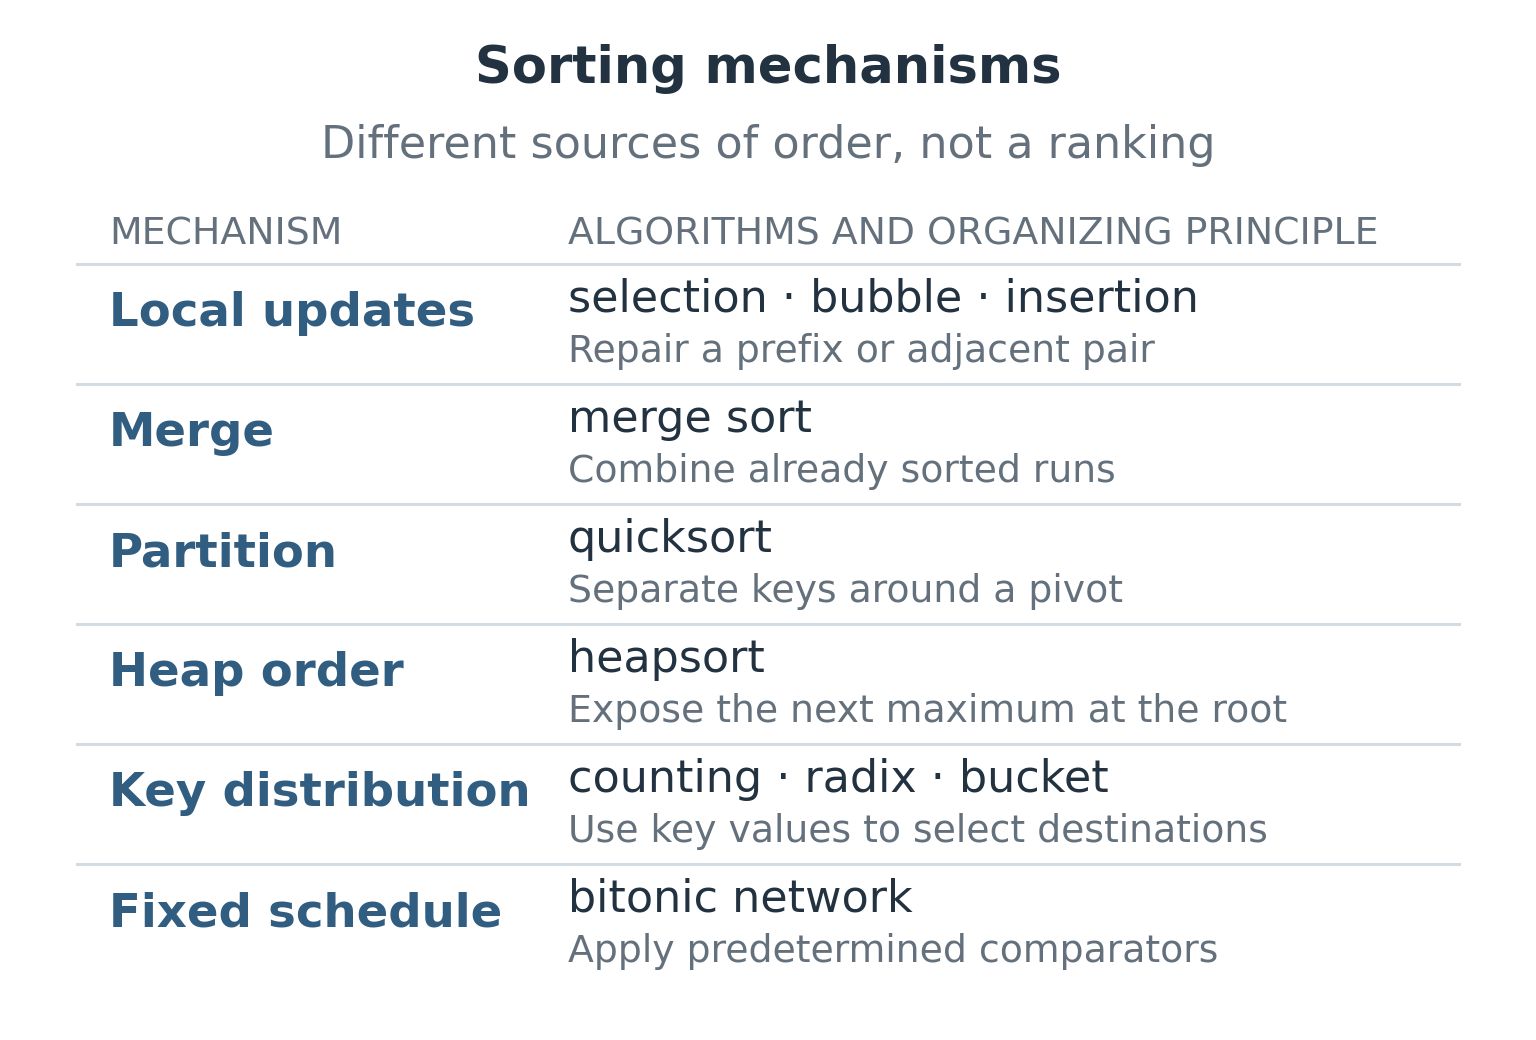

*Figure 1. Record의 순서를 정하는 여섯 가지 방식. 각 행은 어떤 정보를 이용해 정렬하는지 보여 준다. 위아래 순서가 성능 순위를 뜻하지는 않는다. Hybrid sort는 여러 방식을 조합한다.*

‘이진 정렬’이라는 이름만으로는 알고리즘을 특정하기 어렵다. **Binary insertion sort**는 삽입 위치를 binary search로 찾고, **binary heapsort**는 binary heap을 쓴다. **Bitonic sort**는 비교 순서가 정해진 network를 이용한다. 이름이 비슷해도 원리와 time complexity는 서로 다르다.

## 4. Brute force와 random search

### 4.1 Bogosort: 무작위 재시도와 expected cost

배열을 섞고 정렬됐는지 확인한 뒤, 정렬되지 않았다면 다시 섞어 보자. 정렬 여부를 확인하는 것은 쉽지만, 무작위로 섞어서 정답을 찾으려면 얼마나 기다려야 할까?

`[3, 1, 2]`를 나열하는 방법은 `[1,2,3]`, `[1,3,2]`, `[2,1,3]`, `[2,3,1]`, `[3,1,2]`, `[3,2,1]`의 여섯 가지다. 이 중 정렬된 것은 첫 번째뿐이다. 다시 섞어도 앞서 확인한 순서가 나올 수 있다. 이미 검사한 후보를 기억해서 제외하는 방식이 아니기 때문이다.

서로 다른 record $n$개를 나열하는 permutation은 $n!$개이고, 그중 오름차순은 하나뿐이다. 각 shuffle이 독립적이고 모든 permutation을 같은 확률로 만든다고 가정하면, 한 번에 성공할 확률은

$$
p=\frac{1}{n!}.
\tag{5}
$$

이다. 처음 입력이 정렬되지 않았다고 하자. 성공한 shuffle까지 포함해 섞은 횟수를 $X$라 하면 geometric distribution을 따른다.

$$
\begin{aligned}
\Pr(X>m)&=(1-p)^m,\\
\mathbb E[X]&=\frac{1}{p}=n!.
\end{aligned}
\tag{6}
$$

Fisher–Yates shuffle 한 번의 비용은 $\Theta(n)$이다. 정렬 여부를 확인하는 scan은 최대 $O(n)$이 걸린다. 정렬되지 않았다는 것을 scan 도중에 알아내더라도, 배열을 섞는 데 이미 linear time을 썼다. 따라서 처음에 정렬되지 않은 distinct-key 입력의 expected total time은 $\Theta(n\,n!)$이다. 처음부터 정렬돼 있었다면 한 번의 검사로 끝나므로 $\Theta(n)$이다.

Worst case를 “$n!$번”으로 생각하면 안 된다. **유한한 횟수로 upper bound를 정할 수 없기 때문이다.** 어떤 유한한 $m$을 골라도 $(1-p)^m>0$이므로, 그만큼 섞고도 실패할 확률이 남는다. 이상적인 independent shuffle은 확률 1로 종료하지만, 정해진 횟수 안에 성공한다고 보장할 수는 없다. 같은 key가 여러 개라면 정렬 조건을 만족하는 labeled permutation도 여러 개가 되어 성공 확률이 달라진다.

아래 코드는 무한히 기다리지 않도록 shuffle 횟수를 제한한다.


In [2]:
# Requires is_sorted from Section 1.
import random

def bogo_sort_bounded(a, max_shuffles=2000, seed=0):
    """Return (sorted copy or None, shuffles used); never change a."""
    if max_shuffles < 0:
        raise ValueError("max_shuffles must be nonnegative")
    a = list(a)  # Keep the caller's input intact.
    rng = random.Random(seed)
    for attempts in range(max_shuffles + 1):
        if is_sorted(a):
            return a, attempts
        if attempts < max_shuffles:
            rng.shuffle(a)
    return None, max_shuffles

result, attempts = bogo_sort_bounded([3, 1, 2])
assert result is None or result == [1, 2, 3]


Seed를 고정하면 같은 실행 결과를 재현할 수 있다. 다만 pseudorandom generator로 유한 번 실행해 본 결과만으로는, 이론에서 가정한 shuffle의 independence와 uniform distribution을 증명할 수 없다.


**Bogo sort 실험:** [블로그에서 직접 조작하기](https://pilkwangkim.github.io/posts/Sorting-From-Scratch-KR/#lab-sorting-random).


$n$을 하나씩 늘려 보자. 평균적으로 필요한 shuffle 횟수는 매번 일정한 배수로 커지는 것이 아니라 $n+1$배씩 커진다. 실습은 2,000회에서 멈춘다. 제한에 도달했다면 그 횟수 안에 답을 찾지 못했다는 뜻이다. 정렬된 순서가 없다는 뜻은 아니다.

### 4.2 Permutation sort: 모든 permutation 확인

같은 후보를 다시 뽑는 대신, 모든 permutation을 하나씩 확인하는 brute force도 가능하다.


In [3]:
# Requires is_sorted from Section 1.
from itertools import permutations

def permutation_sort(a):
    # Only use tiny inputs: every candidate is a complete ordering.
    for candidate in permutations(a):
        if is_sorted(candidate):
            return list(candidate)

assert permutation_sort([3, 1, 2]) == [1, 2, 3]


Key가 모두 다르면 $n!$개 후보 중 하나가 정답이다. Worst case에서는 마지막 후보까지 확인해야 한다. 이 구현은 길이 $n$인 후보를 하나 만들 때마다 $\Theta(n)$이 걸리므로 worst-case time이 $\Theta(n\,n!)$이다. 언젠가는 답을 찾지만, 앞선 후보를 검사하며 알아낸 대소관계를 거의 재사용하지 못한다.

Brute force는 특정 알고리즘의 이름이 아니라 문제를 푸는 방식을 가리킨다. Selection sort도 brute force로 분류하곤 하지만, quadratic time은 모든 permutation을 확인하는 데 걸리는 시간보다 훨씬 짧다.

## 5. Selection sort: 최솟값 선택

Selection sort는 아직 정렬하지 않은 suffix에서 최솟값을 찾아 그 구간의 맨 앞에 놓는다.

`[4, 1, 3, 2]`의 첫 scan에서는 index `0`의 `4`를 최솟값 후보로 정한다. 다음 값 `1`이 `4`보다 작으므로 `smallest`를 index `1`로 바꾼다. 이후 `3`과 `2`를 확인해도 현재 후보인 `1`보다 작지 않으므로 `smallest`는 그대로다. Scan하는 동안에는 record를 옮기지 않고 최솟값 후보의 index만 갱신한다. Scan이 끝나면 한 번 swap해서 `1`을 맨 앞에 놓는다.

아래에서 세로선 왼쪽은 위치가 확정된 prefix이고, 오른쪽은 최솟값을 더 찾아야 하는 suffix다.

```text
       fixed | remaining
start        | 4 1 3 2
left=0     1 | 4 3 2
left=1   1 2 | 3 4
left=2 1 2 3 | 4
```

Swap으로 오른쪽 suffix의 순서가 바뀌어도 왼쪽 prefix의 위치는 확정돼 있다. 다음 scan에서는 suffix만 확인하면 된다.


In [4]:
def selection_sort(a, key=lambda x: x):
    """Sort a in place and return the same list; not stable."""
    for left in range(len(a) - 1):
        smallest = left
        for j in range(left + 1, len(a)):
            if key(a[j]) < key(a[smallest]):
                smallest = j
        # Everything before left is already final.
        if smallest != left:
            a[left], a[smallest] = a[smallest], a[left]
    return a

values = [4, 1, 3, 2]
result = selection_sort(values)
assert values == [1, 2, 3, 4]
assert result is values  # The caller sees the same modified list.


이 selection sort와 아래의 bubble sort, insertion sort는 전달받은 list 자체를 수정한다. `return a`로 반환하는 것도 복사본이 아니라 같은 list다. `range(len(a) - 1)`은 `left = 0`부터 `n - 2`까지 실행된다. 마지막 한 칸의 위치는 자동으로 정해지므로 따로 탐색할 필요가 없다.

**Invariant**는 반복문의 각 단계에서 계속 유지되는 조건이다. 여기서는 매 반복이 시작될 때, 전체 입력에서 가장 작은 `left`개의 key가 prefix에 오름차순으로 놓여 있어야 한다. 처음에는 prefix가 비어 있으므로 이 조건을 만족한다. 나머지 suffix에서 최솟값을 찾아 prefix 바로 뒤에 놓으면, 조건을 유지하면서 prefix를 한 칸 늘릴 수 있다. 이 과정을 반복해 값이 하나만 남으면 그 값이 마지막 자리에 들어간다.

각 scan의 key 비교 횟수는 차례로 $n-1,n-2,\ldots,1$이다.

$$
\begin{aligned}
C(n)&=\sum_{j=1}^{n-1}j\\
&=\frac{n(n-1)}{2}\\
&=\Theta(n^2).
\end{aligned}
\tag{7}
$$

이미 정렬된 입력에서도 비교 횟수는 같다. Best case, average case, worst case 모두 quadratic한 key 비교가 필요하다. 반면 swap은 최대 $n-1$번이므로, 역순 입력에서는 insertion sort보다 record를 적게 옮길 수 있다. Big O가 같아도 비교 횟수와 쓰기 횟수가 각각 같은 것은 아니다.

이처럼 swap하는 구현은 stable하지 않다. `[2a, 2b, 1]`에서 마지막 `1`과 `2a`를 바꾸면 `[1, 2b, 2a]`가 된다. `<`를 써서 최솟값이 같을 때 먼저 발견한 record를 고르더라도 stability를 보장할 수 없다. 멀리 떨어진 record를 swap하면서 같은 key끼리의 순서가 뒤집힐 수 있기 때문이다.

## 6. Bubble sort: 이웃 비교와 swap

Bubble sort는 왼쪽부터 이웃한 값을 비교하고, 순서가 뒤집혀 있으면 swap한다. 큰 값은 작은 이웃을 만날 때마다 오른쪽으로 이동한다. 따라서 한 pass가 끝나면 남은 값 중 최댓값 하나가 맨 오른쪽에 놓인다.

같은 입력 `[4, 1, 3, 2]`를 넣어 보자. Selection sort는 scan을 마칠 때까지 record를 옮기지 않았다. 반면 bubble sort는 순서가 뒤집힌 이웃을 발견할 때마다 바로 swap한다.

```text
pass 1:
4 1 3 2
1 4 3 2   swap 4,1
1 3 4 2   swap 4,3
1 3 2 | 4 swap 4,2
pass 2:
1 2 | 3 4
pass 3:
1 2 3 4   no swap; stop
```

`j`와 `j + 1`의 비교가 끝나면, 그때까지 확인한 값 중 최댓값 하나가 `j + 1`에 놓인다. 다음 단계에서는 그 최댓값을 오른쪽 이웃과 비교한다. 이 과정을 반복하면 앞부분이 아직 뒤섞여 있더라도 맨 오른쪽에는 최댓값이 온다. 다음 pass에서는 `end`를 줄여 위치가 확정된 이 값을 비교 대상에서 제외한다.


In [5]:
def bubble_sort(a, key=lambda x: x):
    """Stably sort a in place and return the same list."""
    for end in range(len(a) - 1, 0, -1):
        changed = False
        for j in range(end):
            if key(a[j]) > key(a[j + 1]):
                a[j], a[j + 1] = a[j + 1], a[j]
                changed = True
        # A pass with no swaps proves all remaining neighbors are ordered.
        if not changed:
            break
    return a

assert bubble_sort([4, 1, 3, 2]) == [1, 2, 3, 4]


Pass마다 오른쪽의 확정된 suffix가 한 칸씩 늘어난다. `changed`는 불필요한 pass를 막는 early-exit flag다. 이미 정렬된 입력에서는 한 pass 동안 $n-1$번 비교하고 한 번도 swap하지 않으므로 바로 끝난다. Best-case time은 $\Theta(n)$이다. 서로 다른 값이 역순으로 들어오면 모든 pass가 필요해 $\Theta(n^2)$이 걸린다. 서로 다른 key의 모든 permutation이 같은 확률로 들어오는 average case에서도 작업량은 quadratic하다.

한 pass에서 한 번도 swap하지 않았다면 왜 멈춰도 될까? 남은 prefix에서 모든 이웃을 비교했고 순서가 뒤집힌 곳이 없었으므로, 이 prefix는 정렬돼 있다. 오른쪽 suffix에는 이미 큰 값들이 오름차순으로 놓여 있다. 따라서 배열 전체의 정렬이 끝난 것이다. 단순히 “거의 정렬돼 보인다”고 판단해서 멈추는 것이 아니다.

왼쪽 key가 오른쪽보다 클 때만 swap하므로, 같은 key의 두 record는 순서가 뒤집히지 않는다. 따라서 이 구현은 stable하다.

다만 아주 작은 값이 맨 오른쪽에 있다면 비효율적이다. 왼쪽에서 오른쪽으로 진행하는 한 pass에서 이 값은 왼쪽으로 한 칸밖에 이동하지 못한다. 나머지 값들이 거의 정렬돼 있더라도 여러 pass를 거쳐야 한다. Insertion sort는 이런 입력을 훨씬 적은 비교로 처리할 수 있다.

## 7. Insertion sort: 정렬된 prefix에 삽입

Insertion sort는 배열 앞쪽에 정렬된 prefix를 유지한다. 다음 record를 임시 변수에 보관하고, prefix에서 그보다 큰 record들을 오른쪽으로 한 칸씩 밀어 자리를 만든 뒤 삽입한다.

`[4, 1, 3, 2]`에서는 다음과 같이 세 번 삽입한다.

```text
sorted  | unprocessed
4       | 1 3 2
1 4     | 3 2   (shift 4)
1 3 4   | 2     (shift 4)
1 2 3 4 |       (shift 4,3)
```

`item = a[i]`는 record를 임시 변수에 보관할 뿐, Python list에서 삭제하거나 길이를 줄이지는 않는다. 첫 삽입에서 `4`를 오른쪽으로 밀면 배열은 잠시 `[4, 4, 3, 2]`가 되지만, `1`은 `item`에 남아 있다. 이때 index `0`은 **hole**, 즉 다음에 채울 자리로 취급한다. 그 칸의 기존 값은 무시하고 `item`을 써 넣으면 `[1, 4, 3, 2]`가 된다. 중간에 `4`가 두 번 보이더라도 record가 추가되거나 `1`이 사라진 것은 아니다. Hole을 제외한 배열과 `item`을 합쳐 보면 원래 record가 모두 보존돼 있다.


In [6]:
def insertion_sort(a, key=lambda x: x):
    """Stably sort a in place and return the same list."""
    for i in range(1, len(a)):
        item = a[i]
        item_key = key(item)
        j = i - 1
        while j >= 0 and key(a[j]) > item_key:
            a[j + 1] = a[j]  # Shift right; the hole moves left.
            j -= 1
        a[j + 1] = item
    return a

assert insertion_sort([4, 1, 3, 2]) == [1, 2, 3, 4]


$i$번째 반복이 시작될 때 $0$부터 $i-1$까지의 prefix는 정렬돼 있다. 따라서 새 record보다 큰 값들은 prefix의 오른쪽 끝에 모여 있다. 이 값들만 오른쪽으로 한 칸씩 밀고 빈자리에 새 record를 넣으면 길이가 $i+1$인 정렬된 prefix가 된다. 같은 key의 record는 밀지 않으므로 stability도 유지된다.

### 7.1 Inversion과 이동 횟수

**Inversion**은 앞쪽 key가 뒤쪽 key보다 큰 index pair를 뜻한다.

$$
\begin{gathered}
I(A)=\#\{(i,j):\\
i<j,\ k(A_i)>k(A_j)\}.
\end{gathered}
\tag{8}
$$

`[3, 1, 2]`에서는 `3`과 `1`, `3`과 `2`가 역순이다. Index 대신 해당 값을 써서 표시하면 `(3,1)`, `(3,2)`이고, $I=2$다. 정렬된 배열은 $I=0$이다. 서로 다른 key가 역순으로 놓이면 모든 pair가 inversion이므로,

$$
I_{\max}=\binom n2=\frac{n(n-1)}2.
\tag{9}
$$

순서가 뒤집힌 **이웃**을 swap하면 inversion이 정확히 하나 줄어든다. 두 record 사이에는 다른 record가 없으므로, 다른 record들과 이루는 inversion의 수는 달라지지 않는다. 따라서 이웃한 값의 swap만으로 정렬하려면 최소 $I$번의 swap이 필요하다. Bubble sort는 정확히 $I$번 swap하지만, swap할 곳을 찾느라 비교는 더 많이 할 수 있다.

앞의 공통 예제에는 `(4,1)`, `(4,3)`, `(4,2)`, `(3,2)`의 inversion 네 개가 있다. Insertion trace에서도 shift는 $1+1+2=4$번 일어난다. 같은 입력에서 selection sort는 key를 여섯 번 비교한다. Selection sort의 비교 횟수는 배열 길이에 따라 정해지지만, insertion sort의 shift 횟수는 입력의 inversion 수에 따라 달라진다.

Insertion sort의 shift 횟수는 정확히 $I$다. 한 번 shift할 때마다 앞에 있던 큰 record 하나가 삽입할 record의 뒤로 옮겨지고, 두 record 사이의 inversion이 없어진다. 여기에 반복문 제어와 각 record의 최종 삽입에 필요한 $O(n)$ 작업을 더하면 다음과 같다.

$$
T(A)=\Theta(n+I(A)).
\tag{10}
$$


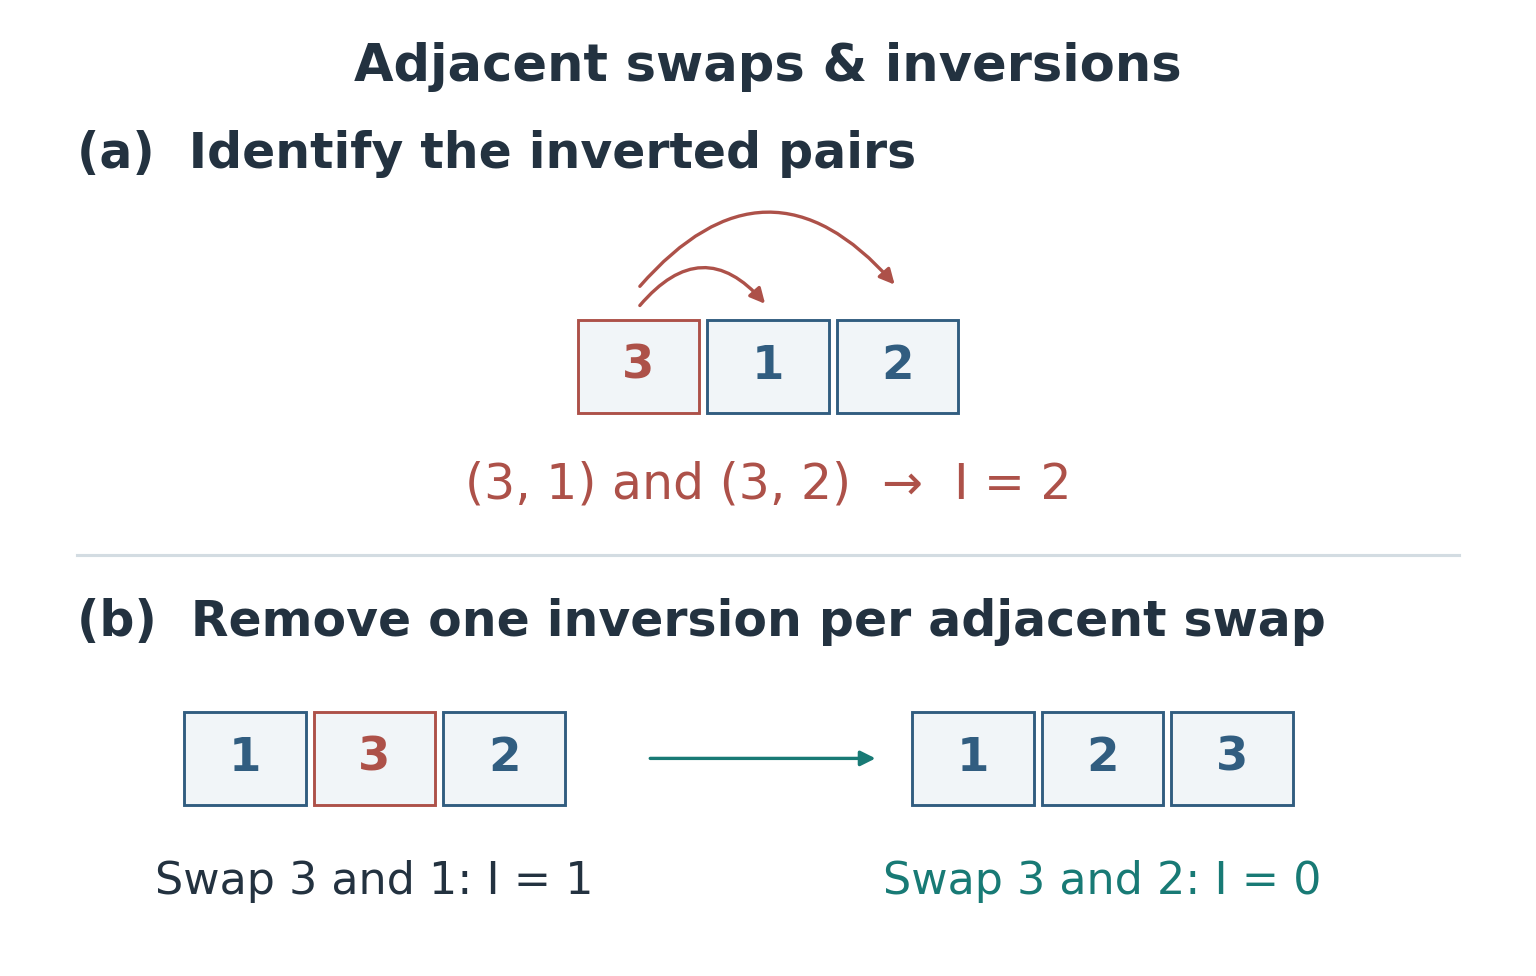

*Figure 2. 순서가 뒤집힌 이웃을 swap하면 inversion이 정확히 하나 줄어든다. Insertion sort도 큰 record를 삽입할 record의 뒤로 shift할 때마다 inversion 하나를 없앤다.*

서로 다른 key의 모든 permutation이 같은 확률로 들어온다면, 각 pair가 inversion일 확률은 $1/2$이다. Linearity of expectation을 적용하면 다음과 같다.

$$
\mathbb E[I]
=\frac12\binom n2
=\frac{n(n-1)}4.
\tag{11}
$$

이 계산에는 서로 다른 pair 사이의 independence가 필요하지 않다. 따라서 average-case time은 quadratic하지만, $I=O(n)$인 입력은 linear time에 정렬할 수 있다. Insertion sort가 작은 배열이나 조금만 뒤섞인 구간을 처리할 때 유용한 이유다.


**Inversion 없애기:** [블로그에서 직접 조작하기](https://pilkwangkim.github.io/posts/Sorting-From-Scratch-KR/#lab-sorting-inversions).


이웃한 값을 직접 swap해 보고, inversion 수를 별도로 실행되는 insertion trace의 shift 횟수와 비교해 보자. Trace의 쓰기 횟수에는 shift뿐 아니라 각 record를 마지막 위치에 넣는 작업도 포함된다. 비어 있지 않은 길이 $n$의 입력에서는 총 쓰기가 $I+(n-1)$번이다. 여기서 마지막 배치에 해당하는 $n-1$번을 빼면 shift 횟수 $I$를 얻는다. 제자리에서 벗어난 것처럼 보이는 원소의 수보다 inversion 수가 이동 횟수를 더 정확하게 설명한다.

## 8. Binary insertion sort: 탐색 비용과 이동 비용

정렬된 prefix에서는 binary search로 삽입 위치를 찾을 수 있다. 비교할 때마다 후보 구간이 절반으로 줄어드므로, $i+1$개의 삽입 위치 중 하나를 찾는 데 $O(\log(i+1))$번 비교하면 된다.

Stability를 유지하려면 key가 같은 record들 **뒤**에 넣어야 한다. 이를 위해 새 key보다 큰 record가 처음 나타나는 위치를 찾는다. 그런 record가 없으면 prefix의 끝에 넣는다. 이 위치를 찾는 것이 **upper bound** search다. 여기서 upper bound는 binary search의 삽입 위치를 뜻하며, Big O에서 쓰는 upper bound와는 다르다.

정렬된 prefix `[1, 2a, 2b, 4]`에 새 record `2c`를 넣는다고 하자. `a`, `b`, `c`는 같은 key를 가진 record를 구별하는 표시다. 기존 순서를 지키려면 index `1`이나 `2`가 아니라 index `3`에 넣어야 한다.

```text
lo hi mid test      update
 0  4   2 2b <= 2c  lo=3
 3  4   3 4 > 2c    hi=3
 3  3     stop: insert at 3
```

비교에는 숫자 key만 쓴다. 탐색 구간 `[lo, hi)`에 record index `hi`는 포함되지 않지만, 삽입 위치로는 `hi`도 가능하다. `lo` 앞의 key들은 새 key 이하이고, `hi`부터 prefix 끝까지의 key들은 새 key보다 크다. `lo = mid + 1` 또는 `hi = mid`로 갱신하면 `mid`를 다시 확인할 필요가 없어진다. 이렇게 확인할 record가 줄어들다가 결국 `lo == hi`가 된다. 그 위치가 삽입할 자리다. 이 예에서는 `4`만 한 칸 밀면 `[1, 2a, 2b, 2c, 4]`가 된다. Binary search로 위치를 찾더라도, 그 자리를 비우려면 별도의 shift가 필요하다.


In [7]:
def binary_insertion_sort(a, key=lambda x: x):
    """Stably sort a in place using upper-bound insertion positions."""
    for i in range(1, len(a)):
        item = a[i]
        item_key = key(item)
        lo, hi = 0, i  # Search the half-open prefix [0, i).
        while lo < hi:
            mid = (lo + hi) // 2
            if key(a[mid]) <= item_key:
                lo = mid + 1  # Equal records stay before the new record.
            else:
                hi = mid
        # Finding lo did not create an empty slot: records must move.
        for j in range(i, lo, -1):
            a[j] = a[j - 1]
        a[lo] = item
    return a

records = [(2, "a"), (1, "a"), (2, "b")]
assert binary_insertion_sort(records, key=lambda x: x[0]) == [
    (1, "a"), (2, "a"), (2, "b")
]


Binary search의 비교 횟수를 모두 더하면 $O(n\log n)$이다. 하지만 맨 앞에 삽입하려면 prefix 전체를 오른쪽으로 밀어야 한다. 역순 입력의 shift 수는 여전히

$$
\begin{gathered}
1+2+\cdots+(n-1)\\
=\frac{n(n-1)}2\\
=\Theta(n^2).
\end{gathered}
\tag{12}
$$

이다. 위 코드의 time complexity는 $\Theta(n\log n+I)$다. 이미 정렬된 입력에서도 매번 binary search를 하므로 best case도 $\Theta(n\log n)$이다. 일반 insertion sort가 정렬된 입력을 linear time에 처리하는 것과 다르다. 새 record가 prefix의 마지막 값 이상인지 먼저 검사하면 이 경우를 linear time에 처리할 수 있지만, 위 구현에는 그 검사가 없다.

**삽입 위치를 찾는 비용과 record를 옮기는 비용은 별개다.** 비교 비용이 크고 reference를 옮기는 비용은 작다면 binary insertion이 유리할 수 있다. 하지만 shift 비용은 그대로 남으므로 배열 전체를 $O(n\log n)$에 정렬할 수 있는 것은 아니다.

## 9. Merge sort: 분할과 stable merge

이미 정렬된 두 list는 앞에서부터 읽으며 합칠 수 있다. 각 list에서 아직 읽지 않은 값 중 최솟값은 맨 앞에 있다. 이 두 값만 비교해 작은 쪽을 output에 넣고, 그 값을 꺼낸 쪽에서만 다음 record를 읽으면 된다.

`[1, 4, 8]`과 `[2, 3, 9]`라면 차례로 `1, 2, 3, 4, 8`을 고른 뒤 남은 `9`를 붙인다. 각 record는 output에 한 번씩 들어간다. 길이가 $p$, $q$인 비어 있지 않은 두 list를 합치는 데 key 비교는 최대 $p+q-1$번이다.

왜 맨 앞의 두 값만 보면 될까? 그 값들이 `4`와 `2`라고 하자. 첫 list에 남은 값은 모두 `4` 이상이고, 둘째 list에 남은 값은 모두 `2` 이상이다. 따라서 두 list에 남은 값 전체에서 최솟값은 `2`다. 뒤쪽을 더 찾아봐도 이보다 작은 값은 없다. 각 list가 이미 정렬돼 있으므로, 비교 한 번으로 output에 넣을 다음 record를 정할 수 있다.

Recursive call은 두 list를 각각 정렬한다. 배열을 반으로 나누기만 하는 것이 아니라, 나눈 각 부분도 같은 방법으로 정렬하는 것이다. Record 네 개를 처리하는 전체 과정을 보면 차이가 분명하다.

```text
split:  [7, 2a, 5, 2b]
        [7, 2a]       [5, 2b]
        [7] [2a]      [5] [2b]
merge:  [2a, 7]       [2b, 5]
        [2a, 2b, 5, 7]
```

여기서 `a`, `b`는 key가 `2`로 같은 record 둘을 구별하는 label이며, 비교에는 쓰지 않는다. `len(a) <= 1`이 될 때까지 recursive call을 반복한다. 그다음 각 호출이 정렬된 결과를 반환하면, 상위 호출이 두 결과를 merge한다. 마지막 merge에서는 `left = [2a, 7]`, `right = [2b, 5]`다. `i = j = 0`에서 시작해 `2a`를 고르면 `i`가 하나 늘고, 다음에 `2b`와 `5`를 고를 때마다 `j`가 하나씩 는다. 이제 `right`를 모두 읽었으므로 `out.extend(left[i:])`로 남은 `7`을 붙인다. 다른 `extend`에는 붙일 값이 없다. `i`, `j`는 각 list에서 다음에 읽을 위치다. 이미 읽은 record를 다시 확인할 필요가 없으므로 두 index는 앞으로만 이동한다.


In [8]:
def merge_sort(a, key=lambda x: x):
    """Return a stable sorted copy; leave a unchanged."""
    if len(a) <= 1:
        return list(a)
    mid = len(a) // 2
    left = merge_sort(a[:mid], key)
    right = merge_sort(a[mid:], key)
    out = []
    i = j = 0
    while i < len(left) and j < len(right):
        if key(left[i]) <= key(right[j]):
            out.append(left[i])  # Left wins ties: preserve stability.
            i += 1
        else:
            out.append(right[j])
            j += 1
    # Only one tail can be nonempty; its records are already sorted.
    out.extend(left[i:])
    out.extend(right[j:])
    return out

records = [(7, "a"), (2, "a"), (5, "a"), (2, "b")]
ordered = merge_sort(records, key=lambda record: record[0])
assert ordered == [(2, "a"), (2, "b"), (5, "a"), (7, "a")]
assert records == [(7, "a"), (2, "a"), (5, "a"), (2, "b")]
assert ordered is not records  # A new list; the input is unchanged.


Merge의 invariant는 `out`에 지금까지 고른 가장 작은 record들이 정렬된 순서로 들어 있다는 것이다. 각 list가 이미 정렬돼 있으므로, 아직 읽지 않은 부분의 최솟값은 맨 앞에 있다. 한쪽을 모두 읽었다면 다른 쪽에 남은 record는 그대로 붙여도 된다.

전체 알고리즘의 정확성은 입력 길이에 대한 induction으로 증명할 수 있다. 길이가 0이나 1이면 이미 정렬돼 있다. 더 짧은 두 입력을 올바르게 정렬했다고 가정하면, 이를 merge한 결과도 원래 record들을 빠짐없이 담은 정렬 결과다. Key가 같을 때 왼쪽을 먼저 고르면 원래 앞쪽 구간에 있던 record가 먼저 나온다. 각 구간 안에서도 recursive call이 같은 key의 순서를 유지하므로, 전체 결과도 stable하다.

### 9.1 Recurrence와 n log n 분석

$n=2^m$이면 절반으로 나누는 일을 $m=\log_2n$번 반복했을 때 record 하나씩 남는다. 한 level에 여러 subproblem이 있지만, 그 길이를 모두 더하면 $n$이다.

Record가 8개라면 처음에는 2개씩 네 번, 다음에는 4개씩 두 번, 마지막에는 8개를 한 번 merge한다. 세 level 모두 처리하는 record는 총 8개다. 입력을 16개로 늘리면 level 수는 두 배가 아니라 하나만 늘어난다. 입력 크기는 두 배씩 늘어도 level은 하나씩 늘기 때문에 logarithm이 나온다. 각 level의 작업량은 다음과 같다.

$$
\begin{aligned}
1\times\Theta(n)&=\Theta(n),\\
2\times\Theta(n/2)&=\Theta(n),\\
4\times\Theta(n/4)&=\Theta(n).
\end{aligned}
\tag{13}
$$

각 줄의 작업량은 모두 $\Theta(n)$이다. 이런 level이 $\log_2n$개 있으므로 전체는 $\Theta(n\log n)$이다. 이를 recurrence로 쓰면,

$$
\begin{gathered}
T(n)=2T(n/2)+\Theta(n),\\
T(n)=\Theta(n\log n).
\end{gathered}
\tag{14}
$$

이다. 길이가 2의 거듭제곱이 아니어도 반으로 나눈 두 부분의 길이는 최대 1 차이다. Recursion depth는 $\lceil\log_2n\rceil$ 이내이므로 같은 asymptotic bound가 성립한다.

$T(n)$ 식처럼 한 호출의 비용을 더 작은 입력에 대한 호출 비용으로 나타낸 식이 **recurrence**다. 앞의 `2`는 recursive call이 두 번이라는 뜻이지, 원래 배열 전체를 두 번 정렬한다는 뜻이 아니다. 뒤에 더하는 linear term은 현재 호출에서 배열을 나누고 합치는 비용이다. Recursion tree에서 level별 작업량을 더하면 이 recurrence의 전체 비용을 구할 수 있다.


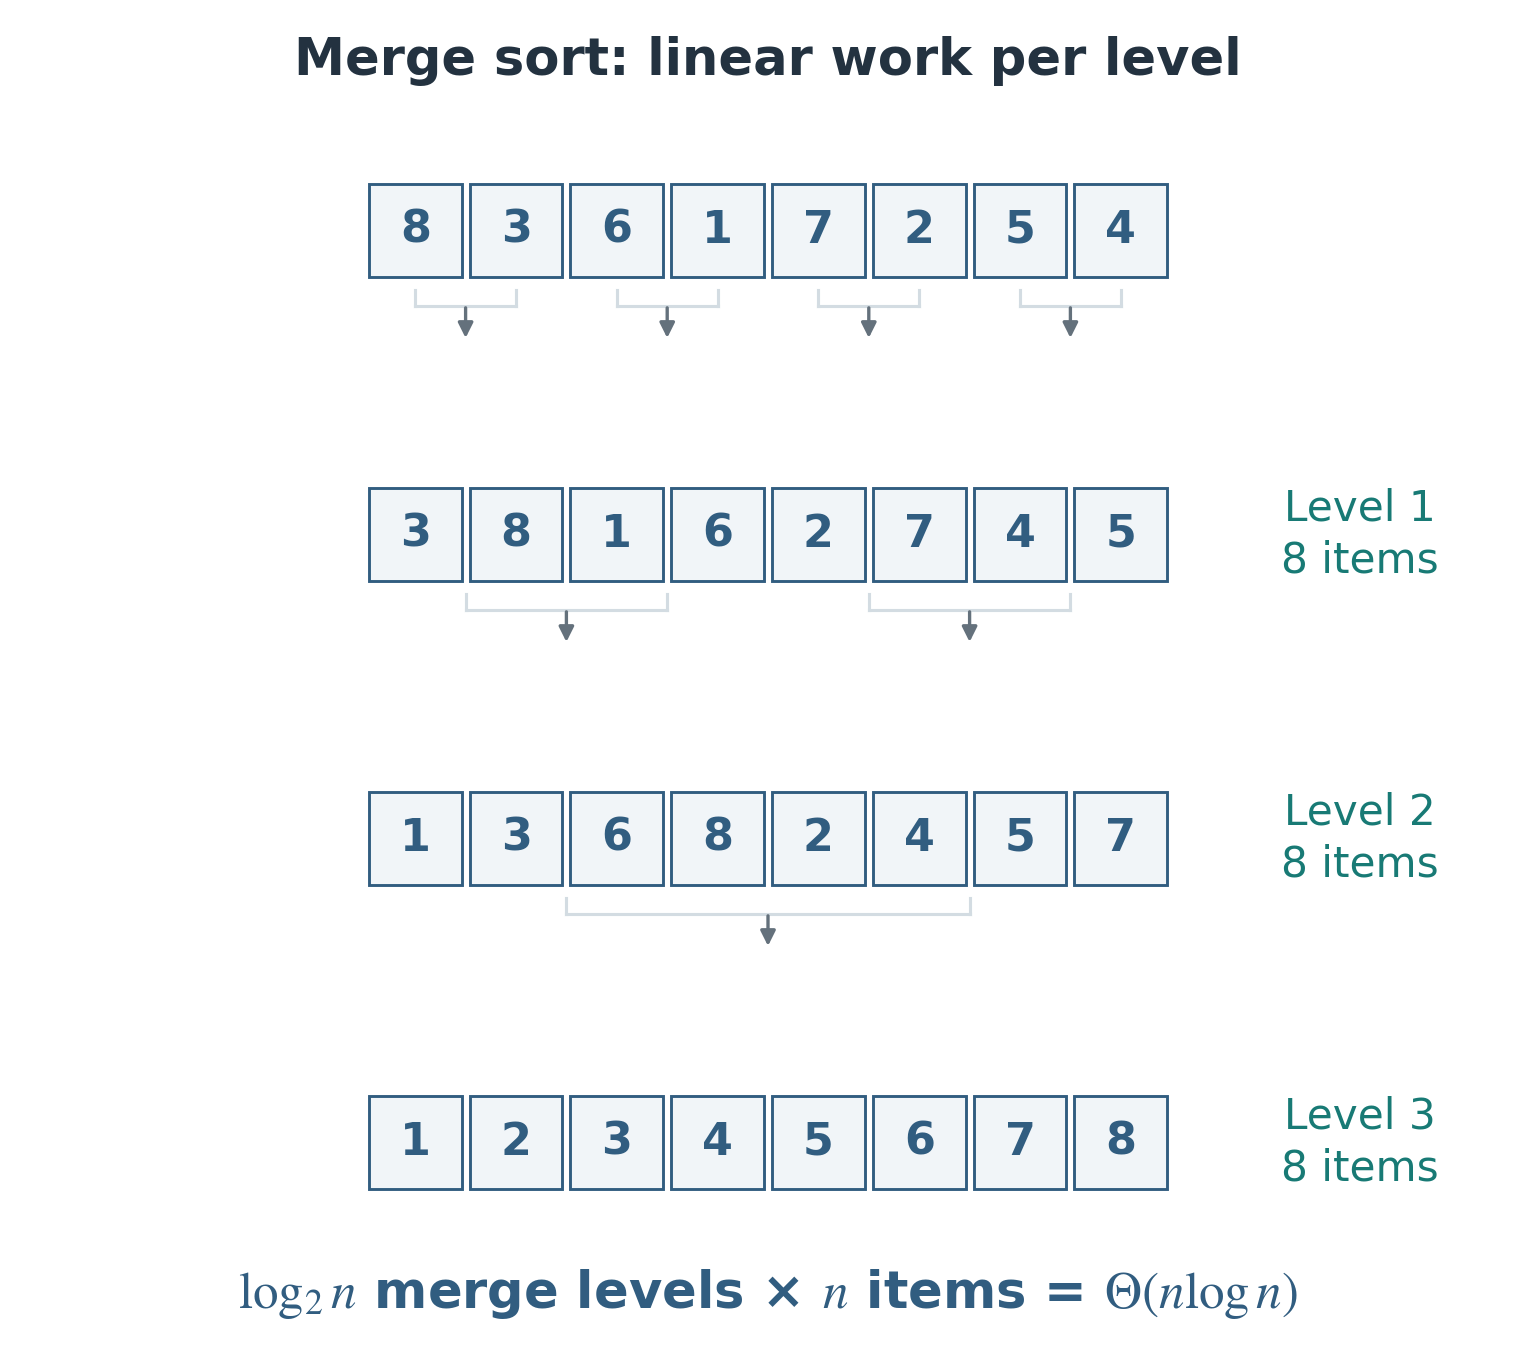

*Figure 3. 각 merge level에서 처리하는 record는 총 여덟 개다. Bracket은 각 merge에 들어가는 두 run을 연결한다. 입력 크기가 $n$이면 반씩 나누는 과정에서 $O(\log n)$개의 level이 생기며, level마다 $O(n)$의 작업이 필요하다.*

Python의 slice도 record reference를 복사하므로 비용이 든다. 다만 이 복사 비용 역시 level당 $\Theta(n)$이며, recurrence의 linear term에 이미 포함돼 있다. 별도의 logarithm을 더 곱할 필요는 없다. 이 구현은 입력이 이미 정렬돼 있어도 나누고 복사하고 합치는 과정을 생략하지 않으므로 $\Theta(n\log n)$이 걸린다.

동시에 필요한 auxiliary storage는 최대 $\Theta(n)$이며, output list와 임시 slice가 여기에 포함된다. Recursion stack은 $O(\log n)$이다. 실행하는 동안 **할당한 공간을 누적해서 더하면** $\Theta(n\log n)$이지만, 그 공간을 한꺼번에 쓰지는 않는다. Peak memory와 cumulative allocation이 다른 이유다. Stable array merge의 time complexity와 space complexity는 [Princeton의 merge-sort reference](https://algs4.cs.princeton.edu/code/javadoc/edu/princeton/cs/algs4/Merge.html)에서도 확인할 수 있다.

이미 정렬된 연속 구간을 **run**이라고 부른다. 아래 예제에서는 두 run을 합치면서 output에 넣을 다음 record를 직접 고를 수 있다.


**Stable merge 직접 해 보기:** [블로그에서 직접 조작하기](https://pilkwangkim.github.io/posts/Sorting-From-Scratch-KR/#lab-sorting-merge).


같은 key에 붙은 label을 따라가 보자. Key가 같을 때 어느 쪽을 먼저 고르느냐에 따라 숫자는 정렬돼 있어도 record의 원래 순서는 뒤집힐 수 있다. Sortedness만 검사하면 stability가 깨진 것을 놓칠 수 있다.

## 10. Quicksort: random pivot과 3-way partition

Merge sort는 배열의 위치를 기준으로 나누고, 각 부분을 정렬한 뒤 합친다. Quicksort는 **key의 값**을 기준으로 나눈다. Pivot을 하나 골라 그보다 key가 작은 record, 같은 record, 큰 record를 각각 모은다. Pivot과 key가 같은 구간은 더 정렬할 필요가 없다.

### 10.1 Partition invariant와 pointer 갱신

3-way partition에서는 pivot과 비교를 마친 record와 아직 확인하지 않은 record를 구간별로 나눠 관리한다.

`[4, 2, 3, 1, 5, 3]`에서 pivot을 `3`으로 정해 보자. 이 예제에서는 pivot을 직접 지정했으므로, 아래 함수를 기본 random seed로 실행한 결과와는 다를 수 있다. 처음에는 `lt = i = 0`, `gt = 5`다. 각 행은 해당 동작을 **마친 뒤**의 상태다.

```text
test   array          lt i gt
start  [4,2,3,1,5,3]   0 0 5
4 > 3  [3,2,3,1,5,4]   0 0 4
3 = 3  [3,2,3,1,5,4]   0 1 4
2 < 3  [2,3,3,1,5,4]   1 2 4
3 = 3  [2,3,3,1,5,4]   1 3 4
1 < 3  [2,1,3,3,5,4]   2 4 4
5 > 3  [2,1,3,3,5,4]   2 4 3
```

첫 swap 뒤에는 index `0`에 새로운 값 `3`이 들어온다. `i = 0`을 유지해야 다음 반복에서 이 값을 확인할 수 있다. 바로 `i`를 늘리면 아직 확인하지 않은 record를 건너뛰게 된다. 반면 `1`을 `lt` 위치와 바꿀 때 그 자리에서 넘어오는 `3`은 equal 구간에 있던 값이다. 이 값은 이미 확인했으므로 두 pointer를 함께 늘려도 된다. 마지막 swap은 같은 자리끼리 바꾸므로 배열은 그대로지만, 그 한 칸도 확인을 마쳤으므로 unknown 구간에서는 제외한다.

Partition이 끝나면 `[2, 1]`은 pivot보다 작고, `[3, 3]`은 같고, `[5, 4]`는 크다. 양옆 구간 안에서는 **아직 정렬이 끝나지 않았다**. `sort(0, 1)`과 `sort(4, 5)`가 이 두 구간을 각각 정렬한다. 각 구간에 속할 record는 이미 정해졌으므로, equal 구간을 넘어 다른 쪽으로 옮길 필요는 없다.

각 구간은 매 단계에서 다음 조건을 만족한다. `[lo, lt)`처럼 쓰는 half-open interval은 `lo`를 포함하고 `lt`는 제외한다. 두 끝점이 같으면 빈 구간이다.

$$
\begin{array}{ccl}
[\mathrm{lo},\mathrm{lt})&:&k(x)<p,\\
[\mathrm{lt},i)&:&k(x)=p,\\
[i,\mathrm{gt}]&:&\text{unknown},\\
(\mathrm{gt},\mathrm{hi}]&:&k(x)>p.
\end{array}
\tag{15}
$$

현재 record의 key가 pivot보다 작으면 왼쪽 구간으로 swap하고 `lt`와 `i`를 함께 늘린다. 같으면 `i`만 늘려 가운데 구간에 포함한다. 크면 오른쪽 구간으로 swap하고 `gt`만 줄인다. 마지막 경우에는 `i`를 옮기면 안 된다. 오른쪽에서 새로 가져온 record를 아직 확인하지 않았기 때문이다.


In [9]:
import random


def quick_sort_3way(a, key=lambda x: x, seed=0):
    """Sort a in place with random-pivot partitioning; return a."""
    rng = random.Random(seed)

    def sort(lo, hi):
        if lo >= hi:
            return
        # Choose a pivot from the inclusive interval [lo, hi].
        pivot = key(a[rng.randrange(lo, hi + 1)])
        lt, i, gt = lo, lo, hi
        while i <= gt:
            current = key(a[i])
            if current < pivot:
                a[lt], a[i] = a[i], a[lt]
                lt += 1
                i += 1
            elif current > pivot:
                a[i], a[gt] = a[gt], a[i]
                gt -= 1  # Recheck the incoming record at i.
            else:
                i += 1
        # The equal region is final. Only the two sides need sorting.
        sort(lo, lt - 1)
        sort(gt + 1, hi)

    sort(0, len(a) - 1)
    return a

assert quick_sort_3way([4, 2, 4, 1, 4, 3]) == [1, 2, 3, 4, 4, 4]


반복할 때마다 아직 확인하지 않은 구간이 한 칸씩 줄어든다. 따라서 record $m$개의 partition에는 $\Theta(m)$이 걸린다. 이후 pivot보다 key가 작은 구간과 큰 구간에만 recursive call을 적용한다. 이 두 구간의 내부 정렬이 끝나면 전체도 작은 값, 같은 값, 큰 값 순서가 된다. 별도의 merge는 필요 없다. [Princeton의 quicksort 설명](https://algs4.cs.princeton.edu/23quicksort/index.php)도 이 3-way invariant를 사용한다.


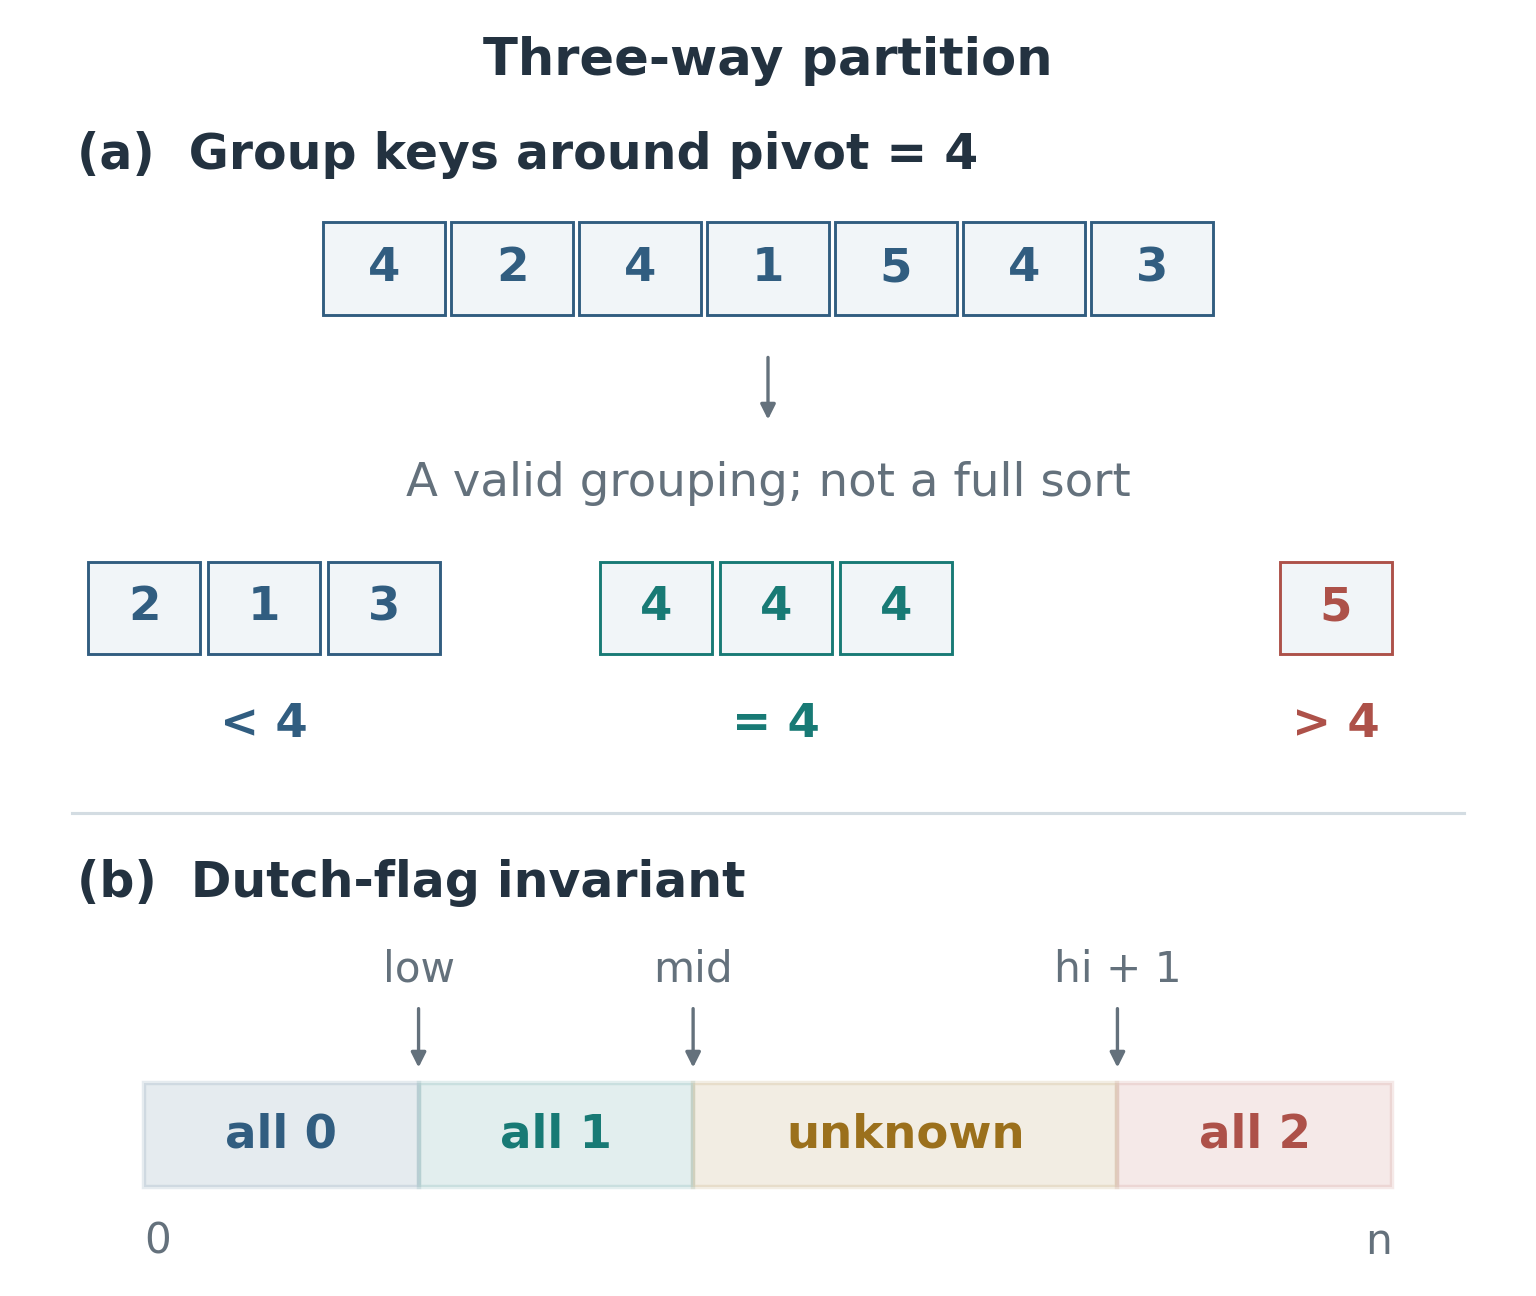

*Figure 4. (a) Pivot 4를 기준으로 나눈 세 구간. 양쪽 구간 안에서는 아직 정렬이 끝나지 않았다. (b) Key가 0/1/2이고 pivot이 1인 Dutch flag의 구간별 조건. Unknown 구간에는 `mid`와 `hi`가 모두 포함된다. `hi+1`부터는 값이 2인 record만 있다.*

### 10.2 분할의 균형과 expected time

Key가 모두 다르고 partition이 매번 비슷한 크기의 두 구간을 만들면, recursion tree에는 $\Theta(\log n)$개의 level이 생긴다. Level당 작업량이 $\Theta(n)$이므로 전체 time complexity는 $\Theta(n\log n)$이다.

반대로 pivot이 계속 남은 값의 최솟값이면 한쪽은 비고 다른 쪽의 길이는 $n-1$이다.

$$
\begin{aligned}
T(n)&=T(n-1)+\Theta(n),\\
T(n)&=\Theta\left(\sum_{m=1}^n m\right)\\
&=\Theta(n^2).
\end{aligned}
\tag{16}
$$

각 record를 같은 확률로 pivot으로 고르면 입력 순서가 나쁘다는 이유만으로 매번 이런 partition이 생기지는 않는다. 물론 우연히 나쁜 pivot만 연달아 고를 가능성은 남는다. **Key가 모두 다른 입력 하나를 고정해 두어도**, 각 호출의 pivot을 uniform distribution에 따라 서로 독립적으로 선택할 때의 expected time은 $\Theta(n\log n)$이다. 하지만 가장 나쁜 pivot sequence에서는 여전히 $\Theta(n^2)$이다.

서로 다른 record 8개에서 pivot을 계속 최솟값이나 최댓값으로 고르면 처리할 구간의 길이가 `8, 7, 6, ...`으로 줄어든다. 아직 정렬되지 않은 같은 record들을 거듭 읽어야 한다. 반대로 중간에 가까운 pivot을 고르면 양쪽 구간이 대략 절반 크기로 줄고, 다음 level에서 각각 다시 작아진다. Random selection이 매번 중간값을 보장하지는 않는다. 다만 특정 입력 순서 때문에 극단적인 pivot이 반복해서 선택되는 문제를 피할 수 있다.

Expected comparison count는 두 key가 직접 비교될 확률을 더해서 구할 수 있다. 정렬했을 때의 순위가 $i<j$인 두 key를 생각해 보자. 표준 randomized quicksort에서 두 key를 비교하는 것은 순위 $i,\ldots,j$ 중 가장 먼저 pivot으로 뽑힌 key가 양 끝 중 하나일 때뿐이다. 그 확률은 $2/(j-i+1)$이다. 모든 pair에 대해 더하면,

$$
\begin{aligned}
\mathbb E[C_n]
&=\sum_{1\le i<j\le n}\frac{2}{j-i+1}\\
&=2(n+1)H_n-4n\\
&=\Theta(n\log n),
\end{aligned}
\tag{17}
$$

이다. 여기서 $H_n=\sum_{j=1}^n1/j=\Theta(\log n)$이다. 이 공식은 key가 모두 다르고, pivot과 record의 대소관계를 한 번의 비교로 판정하는 표준 quicksort model에서 정확히 성립한다. 모든 pair를 실제로 비교한다는 뜻은 아니다. 위 3-way Python 코드는 record 하나를 분류할 때 두 번 비교할 수 있으므로 constant factor는 다르지만, expected comparison count의 증가율은 같다.

예를 들어 정렬 순위가 `2`와 `5`인 두 record를 보자. 그 사이에는 순위 `2, 3, 4, 5`가 있다. 이 중 `3`이나 `4`가 먼저 pivot이 되면 두 record는 서로 다른 recursive call로 넘어가므로 이후에 직접 비교될 일이 없다. `2`나 `5`가 먼저 pivot이 되면 다른 끝점과 비교한다. 네 순위가 먼저 pivot으로 뽑힐 확률은 같으므로, 이 두 record를 비교할 확률은 $2/4$다. 위 식은 이 확률을 모든 pair에 대해 더한 것이다. 덕분에 가능한 recursion tree를 하나씩 나열하지 않고도 expected comparison count를 구할 수 있다.

$H_n$이 logarithmic하게 증가하는 이유는 calculus 없이도 확인할 수 있다. Index 2–3, 4–7, 8–15처럼 항들을 묶어 보자. 완성된 block마다 항 수는 두 배가 되고 각 항의 크기는 절반 정도가 되므로, block의 합은 $1/2$과 $1$ 사이에 있다. 이런 block이 $\Theta(\log n)$개 있다. 마지막에 남는 불완전한 block의 합도 최대 1이므로, 전체 harmonic sum은 logarithmic하게 증가한다.

모든 key가 같으면 3-way partition 한 번으로 처리가 끝나고, 양쪽 recursive call에 남는 record가 없다. 따라서 중복을 허용한 입력 전체에서 best case는 $\Theta(n)$이다. Key가 모두 다른 입력만 고려할 때의 best case인 $\Theta(n\log n)$과는 구분해야 한다.

이 코드는 입력 배열 안에서 정렬하지만 recursion stack은 필요하다. Key가 모두 다를 때 expected recursion depth는 $O(\log n)$이고 worst case는 $O(n)$이다. 큰 입력에서 partition이 계속 한쪽으로 치우치면 정렬을 마치기 전에 Python recursion limit에 걸릴 수도 있다. 작은 쪽에만 recursive call을 적용하고 큰 쪽은 반복문으로 처리하면 stack depth를 제한할 수 있다. 또 멀리 떨어진 record끼리 swap하므로 이 구현은 stable하지 않다.

아래 Dutch flag 예제는 같은 invariant를 `0`, `1`, `2`에 적용한다. Pivot이 `1`로 고정돼 있어 구간 경계와 pointer의 이동을 따라가기 쉽다. 일반적인 key의 quicksort 과정은 1절의 sorting playground에서 확인할 수 있다.


**3-way partition 실습:** [블로그에서 직접 조작하기](https://pilkwangkim.github.io/posts/Sorting-From-Scratch-KR/#lab-sorting-partition).


첫 playground에서는 **첫 record를 pivot으로 고정**한다. 입력 순서를 바꿔 보면 partition이 얼마나 한쪽으로 치우칠 수 있는지 드러난다. 반면 위 Python 함수는 random pivot을 사용한다. Deterministic pivot을 쓰는 구현에 같은 expected bound를 적용하려면 input distribution에 대한 가정이 별도로 필요하다. Playground에서 중복이 많은 입력을 고르면 equal 구간을 따로 처리하는 효과도 볼 수 있다.

## 11. Heapsort: heap 구성과 최댓값 추출

Heap은 완전히 정렬된 배열이 아니다. **Max-heap**의 조건은 모든 parent의 key가 각 child의 key 이상이라는 것이다. 이 조건만으로 root가 최댓값임을 알 수 있다. 하지만 나머지 record 사이의 대소관계까지 모두 정해지는 것은 아니다.

0-based array에서 index $i$의 child는 $2i+1$, $2i+2$다. Heap의 모양은 complete binary tree다. 마지막 level을 제외한 모든 level이 가득 차 있고, 마지막 level도 왼쪽부터 빈틈없이 채운다. 높이는 $\Theta(\log n)$이다.

`[3, 1, 6, 5, 2, 4, 7]`에서는 index `0`의 값 `3`이 root다. 그 child는 index `1, 2`에 있는 값 `1, 6`이다. Index `1`의 child는 index `3, 4`의 값 `5, 2`이고, index `2`의 child는 index `5, 6`의 값 `4, 7`이다. 별도의 node object나 link 없이 배열의 index만으로 tree 구조를 표현할 수 있다.

Index `3`부터 `6`까지는 child가 없는 leaf이므로 이미 heap 조건을 만족한다. Bottom-up repair는 `n // 2 - 1 = 2`에서 시작한다.

```text
start:  [3,1,6,5,2,4,7]
root 2: [3,1,7,5,2,4,6]
root 1: [3,5,7,1,2,4,6]
root 0: [7,5,6,1,2,4,3]
```

마지막 repair에서는 `3`을 더 큰 child인 `7`과 바꾸고, 아래로 내려간 `3`을 다시 `6`과 바꾼다. 반드시 **더 큰 child**를 골라야 한다. 처음에 `5`와 바꾸면 새 parent `5`보다 다른 child `7`이 더 크므로 heap 조건을 만족하지 못한다. 두 child는 각각 자기 subtree의 최댓값이다. 따라서 둘 중 큰 값을 parent 자리로 올리면 적어도 그 자리에서는 heap 조건이 맞는다.

최댓값을 꺼낼 때는 root `7`과 현재 heap의 마지막 값을 바꾼다. 그러면 `[3, 5, 6, 1, 2, 4 | 7]`이 된다. 세로선 왼쪽은 정렬할 값이 남아 있는 heap 구간이고, 오른쪽은 정렬이 끝난 suffix다. Heap 조건을 복구하려면 `3`을 `6`과 바꾸고, 다시 `4`와 바꿔 아래의 첫 상태를 만든다. 최댓값을 꺼내고 heap을 복구하는 과정을 반복하면 전체가 정렬된다.

```text
[6, 5, 4, 1, 2, 3 | 7]
[5, 3, 4, 1, 2 | 6, 7]
[4, 3, 2, 1 | 5, 6, 7]
[3, 1, 2 | 4, 5, 6, 7]
[2, 1 | 3, 4, 5, 6, 7]
[1 | 2, 3, 4, 5, 6, 7]
```

`sift_down(root, end)`에서 `end`는 heap 구간에 포함되지 않는다. 정렬을 마친 suffix는 더 이상 바꾸면 안 되기 때문이다. Heap 조건만 유지하면 남은 구간 전체를 정렬하지 않고도 다음 최댓값을 알 수 있다. 예를 들어 `5`와 `4`가 서로 다른 branch에 있다면, root를 복구하는 데 둘의 대소관계가 필요해질 때만 직접 비교하면 된다.


In [10]:
def heap_sort(a, key=lambda x: x):
    """Sort a in place using a max-heap and return a; not stable."""
    def sift_down(root, end):
        # [0, end) is the active heap. Children are already heaps.
        while 2 * root + 1 < end:
            child = 2 * root + 1
            if child + 1 < end and key(a[child]) < key(a[child + 1]):
                child += 1
            if key(a[root]) >= key(a[child]):
                break
            a[root], a[child] = a[child], a[root]
            root = child

    n = len(a)
    # Leaves need no repair. Build valid subheaps from bottom to top.
    for root in range(n // 2 - 1, -1, -1):
        sift_down(root, n)
    for end in range(n - 1, 0, -1):
        # Put the maximum into its final slot, outside the smaller heap.
        a[0], a[end] = a[end], a[0]
        sift_down(0, end)
    return a

assert heap_sort([3, 1, 6, 5, 2, 4, 7]) == [1, 2, 3, 4, 5, 6, 7]


Sift를 시작할 때 root는 heap 조건을 어길 수 있지만, 두 child subtree는 이미 heap이다. 더 큰 child와 바꾸면 parent 자리에서는 조건을 만족하고, 아래로 내려간 record의 새 자리만 다시 확인하면 된다. 이 과정을 반복하면 subtree 전체가 heap 조건을 만족한다. Bottom-up build는 아래쪽 subtree부터 heap으로 만든 뒤, 이를 이용해 위쪽 parent를 차례로 처리한다.

### 11.1 Bottom-up heap 구성: 왜 linear time인가

“Node가 $n$개이고 높이가 $\log n$이니 $n\log n$”이라는 계산도 upper bound로는 맞다. 하지만 모든 node가 root만큼 내려갈 수 있다고 세기 때문에 실제 비용보다 크게 잡는다. 대략 절반은 leaf라서 이동할 필요가 없고, 4분의 1은 높이 1, 8분의 1은 높이 2다. 높이가 $h$인 node 수는 최대 $n/2^{h+1}+1$개다. 각 node가 내려갈 수 있는 횟수를 높이별로 더하면,

$$
\begin{gathered}
T_{\mathrm{build}}(n)\\
=O\left(n\sum_{h\ge0}\frac{h+1}{2^{h+1}}\right)\\
=O(n).
\end{gathered}
\tag{18}
$$

이다. Node 수를 정수로 세면서 생기는 추가 항을 모두 더해도 $O(\log^2n)$이고, 이 역시 $O(n)$에 포함된다. Build loop 자체도 $\Theta(n)$번 반복하므로 build time은 $\Theta(n)$이다. 빈 heap에 record를 하나씩 삽입하는 방식과는 다르다. 하나씩 삽입해서 구성할 때의 worst-case time은 $O(n\log n)$이다.

Heap을 만든 뒤에는 root를 $n-1$번 꺼낸다. Heap 조건을 한 번 복구하는 데 최대 $O(\log n)$이 걸리므로 heapsort의 worst-case time은 $O(n\log n)$이다. 이 bound는 tight하다. Auxiliary record storage는 $O(1)$이며 recursion은 쓰지 않는다.

위의 sift는 heap 조건을 만족하면 즉시 멈춘다. 따라서 모든 key가 같으면 전체 정렬이 linear time에 끝난다. Key가 모두 다른 입력만 고려하면 표준 binary heapsort의 best case와 worst case는 모두 $\Theta(n\log n)$이다. Bottom-up build의 비용과 중복 key에 따른 차이는 [Princeton의 heap reference](https://algs4.cs.princeton.edu/24pq/)에도 설명돼 있다. Root와 마지막 record를 swap하므로 stability는 유지되지 않는다.


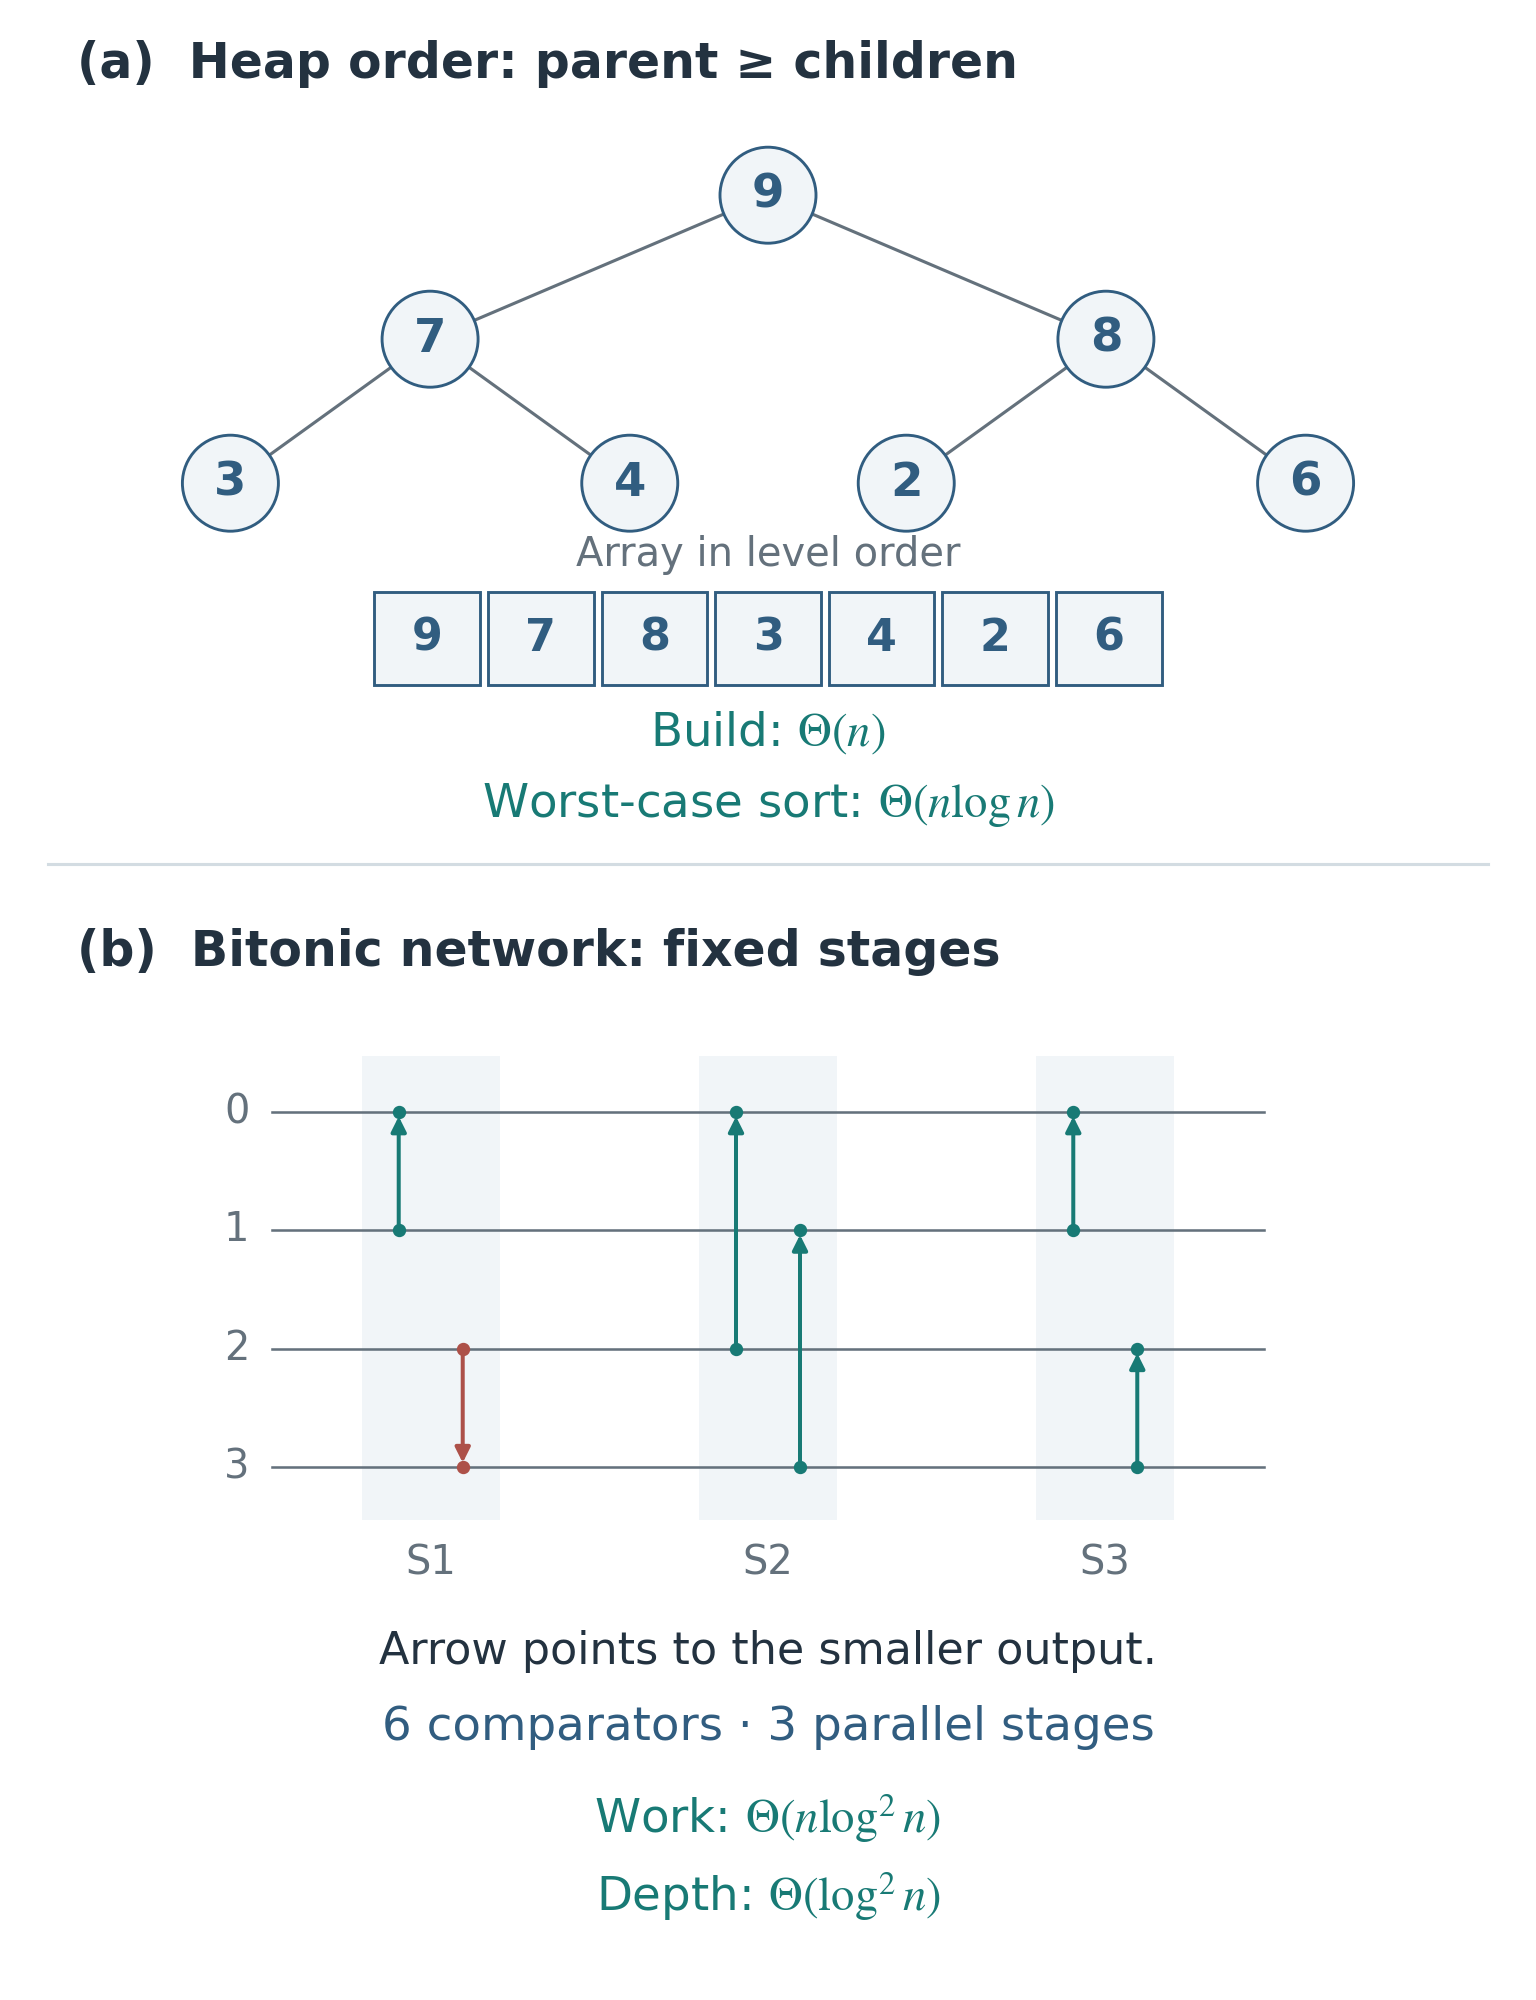

*Figure 5. (a) Max-heap과 이를 level order로 저장한 배열. Parent의 key는 각 child의 key 이상이다. (b) Comparator 여섯 개를 세 stage에 배치한 4-wire bitonic network. 화살표는 작은 값이 나오는 쪽을 가리키며, 같은 stage의 comparator들은 wire를 공유하지 않는다.*

## 12. Comparison sort의 lower bound

Key $n$개가 모두 다르고, 알고리즘이 비교만으로 대소관계를 알아낸다고 하자. 비교 결과는 두 가지이므로, 비교할 때마다 어느 쪽으로 진행하는지를 binary decision tree로 그릴 수 있다. 각 leaf에는 최종 출력 순서가 정해져 있다.

Record 세 개의 이름을 `a`, `b`, `c`라고 하면 가능한 출력 순서는 `abc`, `acb`, `bac`, `bca`, `cab`, `cba`다. 이 이름은 record를 구별할 뿐, 값의 순위를 뜻하지 않는다. 다음과 같은 순서로 비교하면 여섯 경우를 모두 구별할 수 있다.

```text
a < b?
  yes: b < c?
         yes -> abc
         no: a < c?
               yes -> acb
               no  -> cab
  no:  a < c?
         yes -> bac
         no: b < c?
               yes -> bca
               no  -> cba
```

`a = 9`, `b = 2`, `c = 5`이면 답은 차례로 no, no, yes다. 그 결과 `b < c < a`임을 알 수 있으므로 해당 leaf의 출력은 `bca`, 즉 `[2, 5, 9]`다. 어떤 입력은 두 번만 비교해도 끝나지만, 세 번이 필요한 입력도 있다. Yes/no 질문 두 번으로 구별할 수 있는 경우는 최대 네 가지다. 필요한 여섯 가지를 모두 구별하기에는 부족하다. 질문 순서를 어떻게 바꾸더라도 세 번째 질문이 필요한 경우가 생긴다.

입력 key의 상대적인 순서는 $n!$가지다. 올바른 알고리즘은 이 모든 경우를 구별해야 한다. 서로 다른 두 순서가 같은 leaf에 도달하면 둘 다 같은 permutation으로 재배열하므로, 적어도 하나는 잘못된 결과가 된다. 높이가 $h$인 binary tree에는 leaf가 최대 $2^h$개 있으므로,

$$
\begin{gathered}
2^h\ge n!,\\
h\ge\lceil\log_2(n!)\rceil.
\end{gathered}
\tag{19}
$$

이 값이 얼마나 빠르게 증가하는지는 Stirling formula 없이도 구할 수 있다. 곱하는 각 수가 모두 $n$ 이하이므로,

$$
\log_2(n!)\le n\log_2n.
\tag{20}
$$

한편 $n$이 짝수이면 곱의 뒤쪽 $n/2$개 수는 각각 $n/2$ 이상이다.

$$
\begin{aligned}
n!&\ge(n/2)^{n/2},\\
\log_2(n!)&\ge\frac n2\log_2\frac n2.
\end{aligned}
\tag{21}
$$

홀수일 때도 정수로 맞추는 부분만 달라질 뿐 결과는 같다. 두 bound를 합하면 $\log_2(n!)=\Theta(n\log n)$이다. 따라서 **worst-case comparison lower bound**는 $\Omega(n\log n)$이다. Merge sort와 heapsort가 이 증가율로 정렬하므로 bound는 tight하다. [MIT의 정렬 강의](https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-fall-2011/resources/lecture-7-counting-sort-radix-sort-lower-bounds-for-sorting/)도 이 comparison model과 적용 범위를 다룬다.


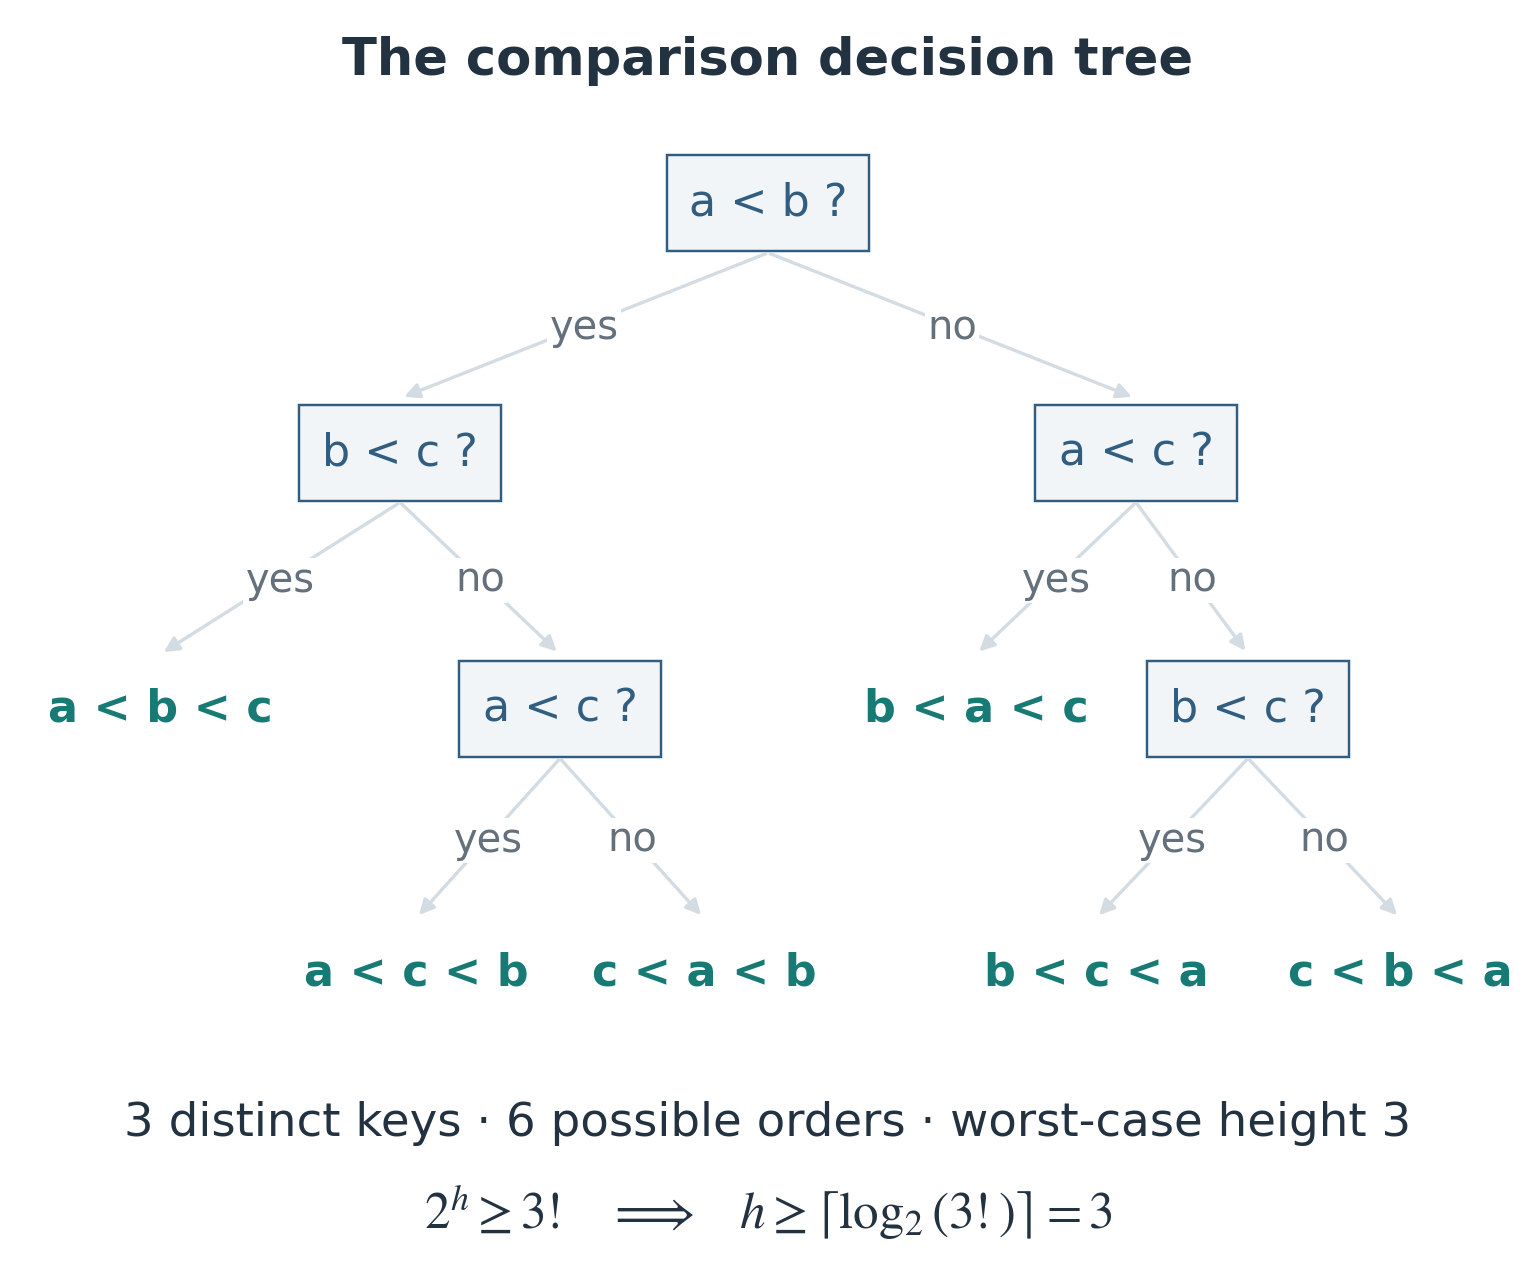

*Figure 6. 결과가 두 가지인 비교 한 번으로 얻는 정보는 최대 1 bit다. 비교 대상을 어떻게 고르든 $n!$가지 순서를 모두 구별할 수 있을 만큼 비교해야 한다.*

모든 입력에 반드시 $n\log n$만큼의 작업이 필요하다는 뜻은 아니다. 이미 정렬된 입력인지 확인하는 데는 linear time이면 충분하다. 또 정수의 digit을 읽거나 key를 array address로 쓰는 알고리즘은 비교 이외의 정보도 이용하므로 이 lower bound의 적용 대상이 아니다. 서로 다른 상대 순서가 같은 확률로 주어진다면 average decision depth에도 $\Omega(n\log n)$ bound가 성립한다. Randomization을 사용해도 comparison model 자체의 이 한계를 넘을 수는 없다.

## 13. Counting sort: histogram과 prefix sum

Key가 $\{0,\ldots,K-1\}$ 범위의 정수라면 그 값을 array index로 바로 쓸 수 있다. 먼저 histogram으로 각 key의 개수를 센다. 그다음 prefix sum으로 key별 record를 넣을 위치를 계산한다.

Key가 `[2, 0, 2, 1, 0]`이면 count는 `[2, 1, 2]`다. 시작 위치는 `[0, 2, 3]`이 된다. 0 두 개가 index 0–1을 차지하고, 1 하나가 index 2, 2 두 개가 index 3–4를 차지하기 때문이다.

Count는 각 key가 **몇 개 있는지**, offset은 그 key를 넣을 구간이 **어디서 시작하는지**를 나타낸다. Key `2`의 첫 위치를 구하려면 `0`과 `1`의 개수를 더하면 된다. 이 record들이 모두 `2`보다 앞에 와야 하기 때문이다. 여기에 `2`의 개수까지 더하면 시작 위치가 아니라 해당 구간 바로 다음의 index가 나온다.

Figure 7처럼 label을 붙이면 각 record가 어디로 이동하는지 확인할 수 있다. `2a`는 key가 `2`이고 identity가 `a`인 record다. Identity는 record와 함께 옮기지만 비교에는 쓰지 않는다.

```text
input: [2a,1a,2b,0a,1b]
count: [1,2,2]
start: [0,1,3]

2a -> 3: [ ·, ·, ·,2a, ·]
1a -> 1: [ ·,1a, ·,2a, ·]
2b -> 4: [ ·,1a, ·,2a,2b]
0a -> 0: [0a,1a, ·,2a,2b]
1b -> 2: [0a,1a,1b,2a,2b]
```

Record 하나를 배치하면 그 key의 cursor만 다음 빈자리로 옮긴다. `2a`를 넣으면 key `2`의 cursor는 `3`에서 `4`로 바뀌고, 나중에 읽은 `2b`는 바로 그 자리에 들어간다. 아래 코드의 `next_slot`은 처음에는 시작 offset을 담는다. 이후에는 key별로 다음에 쓸 output 위치를 가리키므로, 실행이 끝났을 때의 값은 원래 시작 위치와 다르다.


In [11]:
def counting_sort(a, K, key=lambda x: x):
    """Return a stable sorted copy for integer keys in [0, K)."""
    if K < 0:
        raise ValueError("K must be nonnegative")
    count = [0] * K
    for item in a:
        value = key(item)
        if not isinstance(value, int) or not 0 <= value < K:
            raise ValueError("keys must be integers in [0, K)")
        count[value] += 1

    # Exclusive prefix sums: each key begins after all smaller keys.
    next_slot = [0] * K
    for value in range(1, K):
        next_slot[value] = next_slot[value - 1] + count[value - 1]
    out = [None] * len(a)
    for item in a:
        value = key(item)
        out[next_slot[value]] = item
        next_slot[value] += 1  # Advance this key's next free slot.
    return out

records = [(2, "a"), (1, "a"), (2, "b"), (0, "a"), (1, "b")]
assert counting_sort(records, 3, key=lambda record: record[0]) == [
    (0, "a"), (1, "a"), (1, "b"), (2, "a"), (2, "b")
]


Key $v$의 첫 위치는 다음과 같다.

$$
s_v=\sum_{u=0}^{v-1}\operatorname{count}[u].
\tag{22}
$$

Key가 $v$보다 작은 record가 정확히 $s_v$개이므로, key가 $v$인 record들은 그 위치부터 넣어야 한다. 입력을 왼쪽부터 읽으며 해당 구간을 앞에서부터 채우면 같은 key의 record가 원래 순서대로 들어간다. 모든 record가 key에 맞는 자리에 한 번씩 들어가고, 같은 key의 순서도 유지되므로 sortedness, permutation condition, stability를 모두 만족한다.

현재 key의 개수는 합계에서 제외하므로 **exclusive prefix sum**이라고 한다. 위 예제의 시작 위치는 `[0, 1, 3]`이다. 반면 현재 key의 개수까지 포함한 inclusive cumulative count는 `[1, 3, 5]`다. 어느 쪽도 counting sort에 쓸 수 있지만, record를 배치하는 규칙이 그에 맞아야 한다. 흔히 쓰는 다른 구현은 inclusive count를 해당 구간 바로 다음의 index로 쓴다. 그리고 입력을 오른쪽부터 읽으면서 해당 count를 하나 줄인 뒤 그 자리에 record를 넣는다. 이 끝 위치를 위 코드의 시작 offset처럼 쓰면서 왼쪽부터 읽고 cursor를 늘리면, 잘못된 index에 쓰거나 stability를 잃게 된다.

입력 $n$개를 두 번 읽고, 길이 $K$인 array를 초기화하고 prefix sum을 계산한다.

$$
\begin{gathered}
T(n,K)=\Theta(n+K),\\
S(n,K)=\Theta(n+K).
\end{gathered}
\tag{23}
$$

“Linear time”이라고만 말하면 key 범위 $K$가 계산에서 빠지기 쉽다. $K=O(n)$처럼 key 범위도 제한돼 있어야 $n$에 대해 linear time이라고 할 수 있다. ID가 다섯 개뿐이어도 그 값이 0부터 백만까지 흩어져 있으면, 위 구현에는 1,000,001개의 histogram slot이 필요하다. Key 범위에 비해 실제로 등장하는 값이 적다면 비효율적이다.

음수가 있어도 최솟값 $m$을 알고 있으면 모든 key에서 이 값을 빼면 된다. `key(item) - m`을 index로 쓰고, 범위는 $K=\max k-\min k+1$로 잡는다. Array index만 바뀔 뿐 key 사이의 대소관계는 유지된다. 숫자만 정렬한다면 histogram의 count만큼 각 숫자를 output에 써도 된다. 하지만 record 전체와 stability를 유지하려면 위처럼 각 record를 제자리에 넣는 scatter가 필요하다. Prefix count와 scatter는 [Princeton의 key-indexed counting·radix 자료](https://www.cs.princeton.edu/courses/archive/fall12/cos226/lectures/51StringSorts-2x2.pdf)에서도 핵심 연산이다.

## 14. LSD radix sort: digit별 stable 정렬

Counting sort는 **전체 key**의 가능한 값마다 histogram slot이 필요하다. Radix sort는 key 전체가 아니라 digit별로 나눠 처리한다. Base $b$에서 nonnegative integer $x$의 digit $j$는

$$
\operatorname{digit}_j(x)
=\left\lfloor\frac{x}{b^j}\right\rfloor\bmod b.
\tag{24}
$$

이다. **LSD**는 least significant digit부터 처리한다는 뜻이다. 일의 자리, 십의 자리, 백의 자리 순으로 정렬하되, 매 pass가 stable해야 한다. 자릿수가 짧은 숫자는 앞에 0을 붙여 자릿수를 맞춘 것처럼 처리한다.

`x = 237`, `place = 10`, `base = 10`이라면 먼저 `237 // 10 == 23`으로 일의 자리를 버린다. 여기에 `23 % 10`을 적용하면 오른쪽 끝의 숫자 `3`, 즉 원래 숫자의 십의 자리만 남는다. `place = 1`이면 `7`, `place = 100`이면 `2`가 나온다. 매번 `place`에 `base`를 곱하면 문자열로 바꾸지 않고도 한 자리씩 왼쪽으로 이동할 수 있다.


In [12]:
# Requires the stable counting_sort from Section 13.
def radix_sort_nonnegative(a, base=10):
    """Return a sorted copy of nonnegative integers, one digit per pass."""
    if base < 2:
        raise ValueError("base must be at least 2")
    if any(not isinstance(x, int) or x < 0 for x in a):
        raise ValueError("expected nonnegative integers")
    out = list(a)
    if not out:
        return out
    maximum = max(out)
    place = 1
    while place <= maximum:
        out = counting_sort(
            out, base, key=lambda x: (x // place) % base
        )
        place *= base
    return out

assert radix_sort_nonnegative([170, 45, 75, 90, 802, 24, 2, 66]) == [
    2, 24, 45, 66, 75, 90, 170, 802
]


### 14.1 Stability와 digit 순서의 보존

Figure 7의 tagged record 네 개를 정렬하면 다음과 같다.

```text
input:       [21a, 13a, 21b, 12a]
units keys:  [  1,   3,   1,   2]
after units: [21a, 21b, 12a, 13a]
tens keys:   [  2,   2,   1,   1]
after tens:  [12a, 13a, 21a, 21b]
```

일의 자리 pass가 끝나도 `21`은 `12`보다 앞에 있다. 이 단계에서는 전체 숫자가 아니라 일의 자리만 기준으로 정렬했기 때문이다. 다음 십의 자리 pass에서 `12a`와 `13a`는 모두 십의 자리가 `1`인 그룹으로 들어간다. 이 pass가 stable하면 앞서 맞춰 둔 `12a` → `13a` 순서가 유지된다. 결과적으로 십의 자리가 먼저 순서를 결정하고, 십의 자리가 같을 때 일의 자리 순서를 따르게 된다. 전체 key가 같은 `21a`와 `21b`도 원래 순서를 유지한다.

첫 pass가 끝나면 가장 낮은 digit을 기준으로 정렬된다. $j$번의 pass를 마친 뒤 낮은 쪽 $j$개 digit을 기준으로 정렬돼 있다고 가정하자. 다음 pass에서는 digit $j$의 값이 작은 record부터 모은다. Digit $j$의 값이 다르면 이 자리가 이전에 처리한 자리들보다 높으므로 새 순서가 맞다. Digit $j$의 값이 같으면 stability 덕분에 낮은 쪽 $j$개 digit의 기존 순서가 유지된다. 따라서 낮은 쪽 $j+1$개 digit을 기준으로 정렬된다. 이 induction을 모든 digit에 적용하면 전체 숫자도 올바른 순서가 된다.

예를 들어 `[12, 11]`은 일의 자리 pass 뒤에 `[11, 12]`가 된다. 두 숫자의 십의 자리는 모두 `1`이다. 십의 자리 pass가 unstable해서 둘을 다시 바꾸면 `[12, 11]`이 되어, 앞서 맞춘 일의 자리 순서가 뒤집힌다. 따라서 LSD radix sort에서 stability는 선택사항이 아니다. 전체 key를 올바르게 정렬하려면 꼭 필요하다.


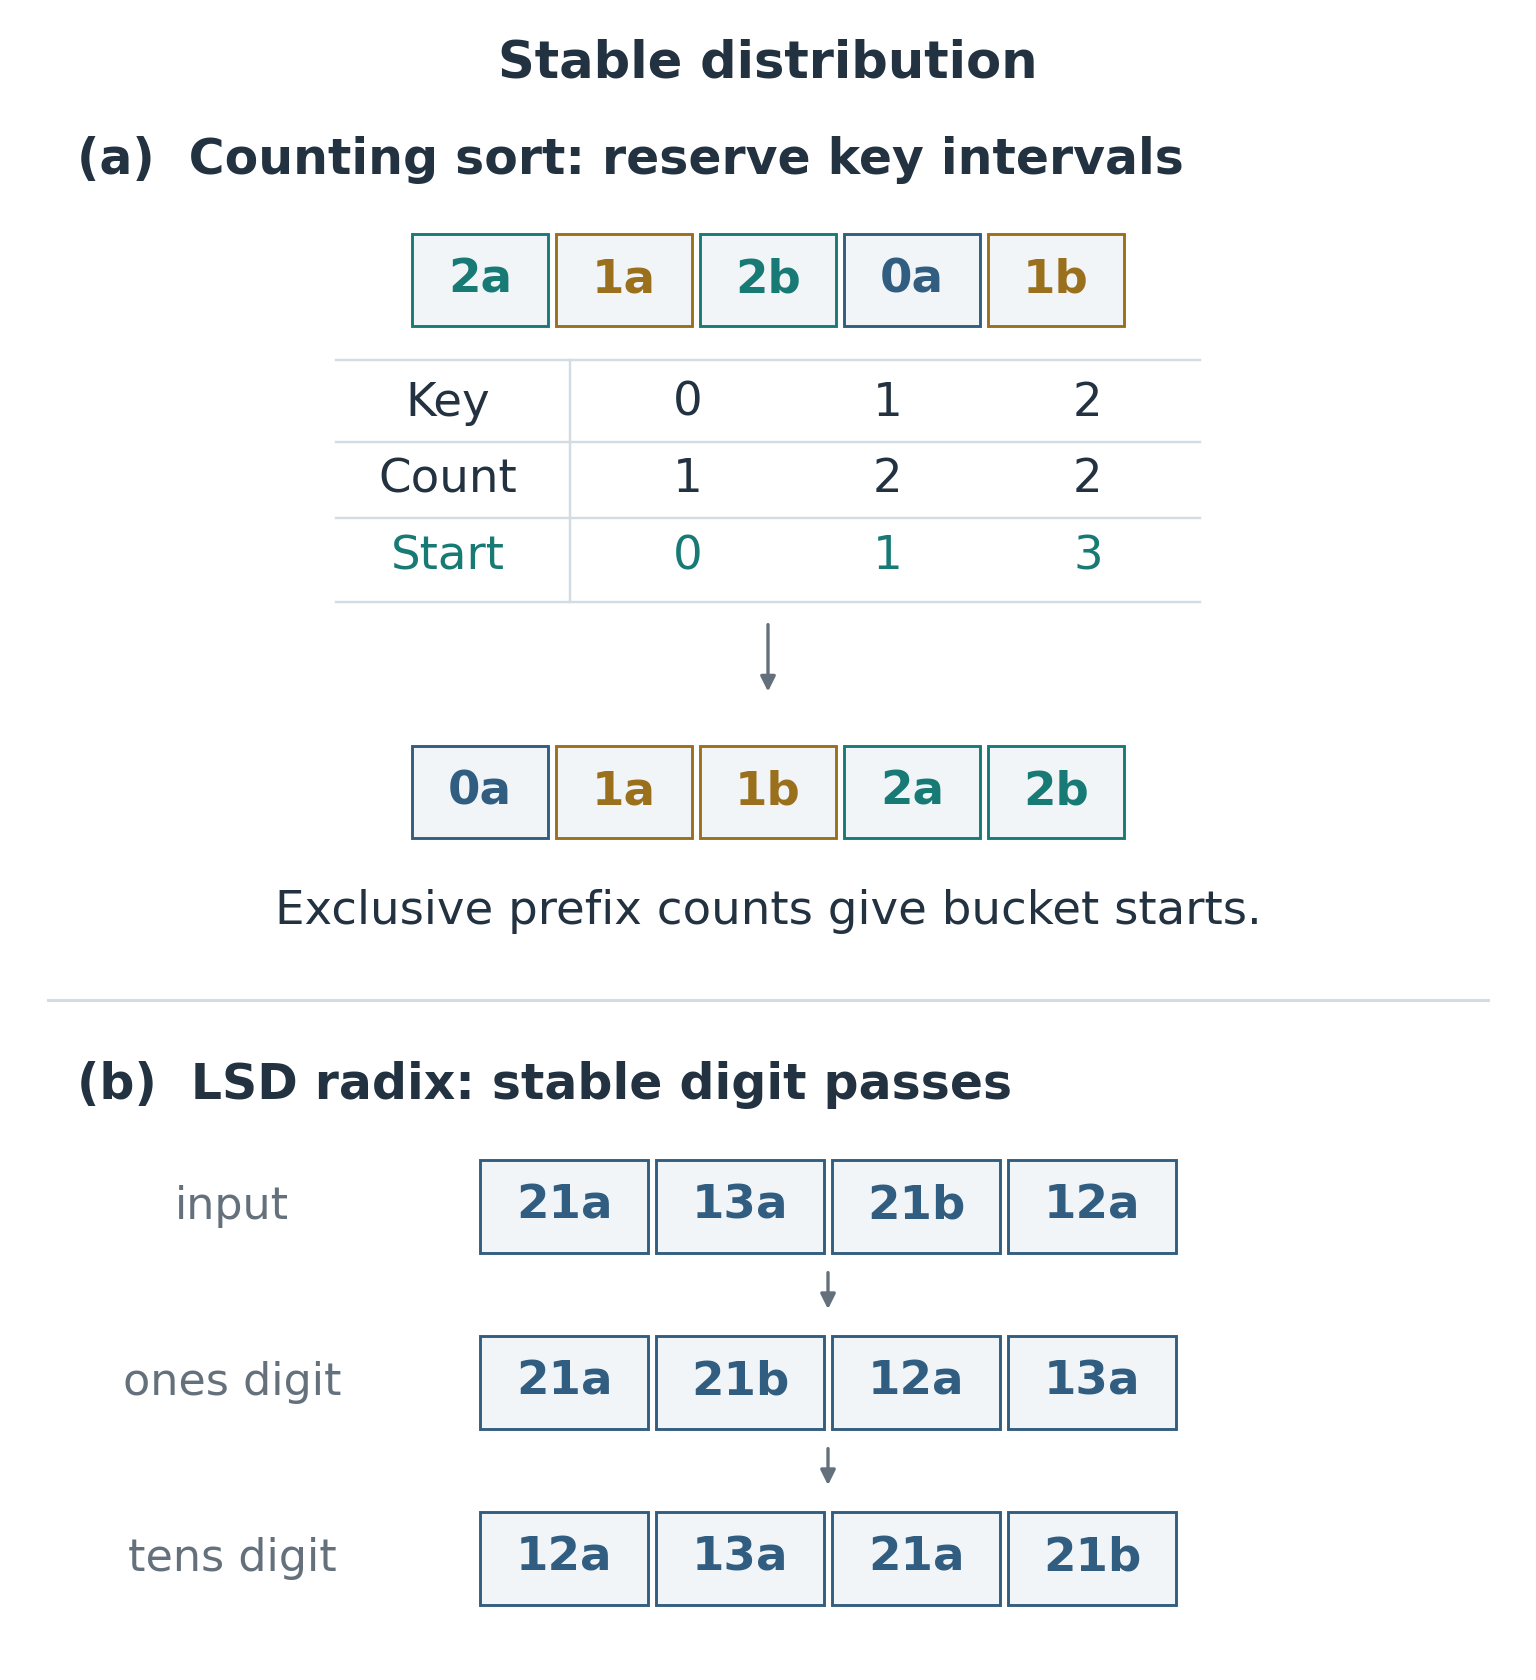

*Figure 7. (a) Count와 exclusive prefix sum으로 key별 output 구간을 정한다. (b) 일의 자리와 십의 자리를 차례로 정렬한다. 각 pass가 stable하므로 낮은 자리에서 맞춘 순서가 다음 pass에서도 유지된다. Label로 각 record의 이동을 추적할 수 있다.*

Pass가 $d$번이고 radix가 $b$이면, 초기 scan과 복사를 포함한 time complexity는 $\Theta(n+d(n+b))$다. 한 번 이상 digit pass를 실행할 때 peak auxiliary storage는 $\Theta(n+b)$이고, 모두 0이라 pass를 생략하면 $\Theta(n)$이다. 최댓값 $M$이 양수이면 $d=\lfloor\log_bM\rfloor+1$이다. 모든 값이 0이어도 초기 작업에 $\Theta(n)$이 걸린다. 흔히 쓰는 간단한 upper bound는

$$
\begin{gathered}
T(n,b,d)=O(d(n+b)),\\
d\ge1.
\end{gathered}
\tag{25}
$$

이다. Fixed-width machine integer를 쓰고 digit width도 고정하면 $d$, $b$를 상수로 볼 수 있으므로 $n$에 대해 linear time이다. 정수의 길이에 제한이 없다면 digit 수와 정수 연산의 bit cost까지 고려해야 한다. Radix를 키우면 pass는 줄지만 histogram은 커진다. 따라서 실제로 사용할 radix를 고를 때는 memory와 cache의 영향도 고려한다.

Signed integer도 값의 범위를 알면 모든 key에서 같은 최솟값을 빼 nonnegative key로 바꿀 수 있다. Fixed-width 구현에서는 sign bit를 처리해 올바른 순서로 변환하는 방법도 쓴다. 이런 처리 없이 two's-complement bit pattern을 unsigned magnitude로 읽으면 음수가 잘못된 위치에 놓인다.


**Counting·radix 배치 과정:** [블로그에서 직접 조작하기](https://pilkwangkim.github.io/posts/Sorting-From-Scratch-KR/#lab-sorting-distribution).


전체 key를 한 번에 처리하는 counting sort와 base 2·10의 stable LSD pass를 비교해 보자. Label을 따라가면 digit이 같은 record 사이에서 이전 순서가 유지되는지 확인할 수 있다. Key 비교를 줄였다고 다른 비용까지 없어지는 것은 아니다. Histogram 갱신, prefix sum 계산, record 쓰기에도 비용이 든다.

## 15. Bucket sort: 구간을 나누는 방법과 input distribution

Bucket sort는 key의 범위를 여러 구간으로 나누고, 각 값을 해당 bucket에 담는다. 그런 다음 bucket 안을 각각 정렬하고, 작은 구간의 bucket부터 차례로 이어 붙인다. Counting sort와 달리 하나의 bucket에 서로 다른 key가 들어갈 수 있으므로, bucket 안을 정렬하는 알고리즘도 필요하다.

예를 들어 `[0.78, 0.17, 0.39, 0.26, 0.72]`를 bucket 네 개에 나누어 보자. 각 구간은 `[0, 0.25)`, `[0.25, 0.50)`, `[0.50, 0.75)`, `[0.75, 1)`이다. Key에 4를 곱한 뒤 소수점 아래를 버리면 bucket 번호가 나온다. `0.39`는 `floor(4 * 0.39) = 1`이므로 bucket `1`에 넣는다.

```text
after distribution:
bucket 0: [0.17]
bucket 1: [0.39, 0.26]
bucket 2: [0.72]
bucket 3: [0.78]

sort within bucket 1: [0.26, 0.39]
concatenate:
[0.17,0.26,0.39,0.72,0.78]
```

나누어 담기만 해서는 같은 bucket에 들어간 `0.39`와 `0.26`의 순서가 맞지 않는다. 둘의 순서는 insertion sort로 바꿔야 한다. 하지만 이 값들을 `0.72`, `0.78`과 비교할 필요는 없다. 어느 bucket에 들어갔는지만 봐도 어느 쪽이 작은지 알 수 있기 때문이다.

$[0,1)$의 값을 같은 폭의 bucket $k$개로 나누면 bucket index는 $\lfloor kx\rfloor$다.


In [13]:
# Requires insertion_sort from Section 7 for each local bucket.
def bucket_sort_unit(a, bucket_count=None):
    """Return a sorted copy of values in [0, 1)."""
    n = len(a)
    if bucket_count is None:
        bucket_count = max(1, n)
    if bucket_count < 1:
        raise ValueError("bucket_count must be positive")
    buckets = [[] for _ in range(bucket_count)]
    for x in a:
        if not 0 <= x < 1:
            raise ValueError("expected keys in [0, 1)")
        buckets[int(bucket_count * x)].append(x)
    out = []
    for bucket in buckets:
        insertion_sort(bucket)
        out.extend(bucket)
    return out

assert bucket_sort_unit([0.78, 0.17, 0.39, 0.26, 0.72], 4) == [
    0.17, 0.26, 0.39, 0.72, 0.78
]


앞쪽 bucket의 값은 모두 뒤쪽 bucket의 값보다 작다. 따라서 각 bucket 안을 정렬한 뒤 이어 붙이면 전체 배열도 정렬된다. 위 구현은 입력 순서대로 append하고 stable한 insertion sort를 쓰므로 같은 값의 순서도 보존한다. 일반적인 record를 처리하도록 확장할 때는 bucket을 정할 때와 bucket 안을 정렬할 때 같은 key를 써야 한다.

Bucket $j$에 들어간 record 수를 $n_j$라고 하자. Bucket 안에서 수행하는 insertion sort의 총비용은 $\sum_j n_j^2$에 일정한 constant factor를 곱한 값 이내이고, bucket에 나눠 담고 이어 붙이는 데 $O(n+k)$가 든다. 각 record의 bucket index가 서로 **independent**하고 **uniform distribution**을 따른다면 다음 식이 성립한다.

$$
\begin{gathered}
\mathbb E\left[\sum_{j=0}^{k-1}n_j^2\right]\\
=n+\frac{n(n-1)}{k}.
\end{gathered}
\tag{26}
$$

제곱을 풀어 쓰면, record 하나당 1을 더하고 같은 bucket에 들어간 서로 다른 record의 ordered pair마다 1을 더하는 셈이다. 각 pair가 같은 bucket에 들어갈 확률은 $1/k$이므로 위 식을 얻는다. 따라서 expected time은 다음과 같다.

$$
O\left(n+k+\frac{n^2}{k}\right).
\tag{27}
$$

$k=\Theta(n)$이면 위 가정 아래에서 expected time이 $\Theta(n)$이다. Bucket을 사용하기만 하면 linear time이 되는 것은 아니다. 모든 값이 하나의 bucket에 역순으로 몰리면 그 안의 insertion sort에 $\Theta(n^2)$이 걸린다. Record별 bucket index가 각각 uniform distribution을 따르더라도, record 사이에 dependence가 있으면 위 pair의 확률 계산을 그대로 적용할 수 없다.

Bucket 크기의 제곱을 보면 input distribution이 왜 중요한지 알 수 있다. Record 여덟 개가 각각 다른 bucket에 들어가면 합은 `8 * 1² = 8`이다. 네 개씩 두 bucket에 들어가면 `2 * 4² = 32`, 여덟 개가 하나에 몰리면 `8² = 64`가 된다. 이 숫자는 정확한 비교 횟수가 아니라 비용의 upper bound에 들어가는 항이다. Uniform random input이라고 모든 bucket에 하나씩 들어가는 것은 아니다. 식 (26)이 보장하는 것은, bucket 수를 record 수에 비례하게 잡으면 이 제곱합의 expected value가 linear하게 증가한다는 것이다.

세 가지 distribution-based sort는 서로 다른 정보를 이용한다. **Counting sort**는 key 값마다 별도의 구간을 배정한다. **Bucket sort**는 일정 범위의 key를 같은 bucket에 모은 뒤 그 안에서 정렬한다. **Radix sort**는 digit 하나를 기준으로 배치하는 작업을 반복하고, 앞선 digit으로 정한 순서는 stability로 보존한다. 비교 연산이 적다고 해서 모두 linear time인 것은 아니다. 각 알고리즘이 어떤 key 구조와 입력 조건을 이용하는지 확인해야 한다.

## 16. Hybrid sort: 여러 알고리즘을 함께 쓰는 이유

### 16.1 Python sort: run·Timsort·Powersort

일반적인 Python 프로그램에서는 `sorted(records, key=...)`나 `records.sort(key=...)`를 쓰면 된다. `sorted`는 새 list를 반환하고, `list.sort()`는 원래 list를 바꾼 뒤 `None`을 반환한다. Python은 record마다 key function을 한 번만 호출하며 stable sort를 보장한다. 이는 앞서 작성한 짧은 예제 함수의 특성이 아니라 Python API가 보장하는 동작이다. [Python Sorting HOWTO](https://docs.python.org/3/howto/sorting.html).


In [14]:
students = [
    {"name": "Mina", "score": 90},
    {"name": "Joon", "score": 75},
    {"name": "Ara", "score": 90},
]
ordered = sorted(students, key=lambda student: student["score"])
assert [student["name"] for student in ordered] == ["Joon", "Mina", "Ara"]


**Run**은 배열에서 이미 순서대로 놓여 있는 연속 구간이다. Adaptive merge sort는 이런 run을 찾고, 너무 짧으면 insertion 방식으로 길이를 늘린 뒤 merge한다. 이미 맞춰진 순서를 처음부터 다시 정렬할 필요가 없는 것이다. 입력 전체가 하나의 run이면 배열을 한 번 scan하는 linear time만으로 끝난다. Comparison sort에서도 best case는 linear time이면서 worst case는 $O(n\log n)$일 수 있다.

예를 들어 `[1, 4, 7, 2, 3, 8, 6, 5]`에서 앞의 `[1, 4, 7]`, `[2, 3, 8]`은 ascending run이고, 마지막 `[6, 5]`는 descending run이다. 마지막 run을 뒤집으면 `[5, 6]`이 된다. 앞의 두 run을 merge해 `[1, 2, 3, 4, 7, 8]`을 만들고, 여기에 `[5, 6]`을 merge하면 끝난다. Record 하나짜리 구간부터 merge하지 않고, 각 run 안에서 이미 맞춰진 순서를 활용한 것이다. 이 예시는 run-based 정렬의 원리를 보여 준다. 특정 Python 버전이 이 여덟 record에 적용하는 run 확장 길이나 merge 순서를 그대로 재현한 것은 아니다.

**짧은 run의 길이를 늘린다**는 것은 바로 뒤에 있는 record를 기존 run의 알맞은 위치에 삽입하는 작업이다. 정해 둔 최소 run 길이에 도달하거나 입력이 끝날 때까지 반복한다. 가짜 key를 추가하는 padding과는 다르다. Insertion에 비용이 들지만 작은 구간에서만 수행한다. 대신 나중에 지나치게 짧은 run을 여러 번 merge하는 비용을 줄일 수 있다.

Descending run을 뒤집을 때도 stability를 지켜야 한다. `[3a, 3b, 2a]`를 그대로 뒤집으면 `[2a, 3b, 3a]`가 되어 같은 key `3`의 순서가 바뀐다. 간단하게 구현하려면 **strictly descending**인 run만 뒤집으면 된다. CPython 3.14는 같은 key가 연속된 구간을 먼저 뒤집은 다음 전체 run을 뒤집는다. 이렇게 하면 descending run에 같은 key가 있어도 원래 순서를 복원할 수 있다. 두 방식 모두 같은 key의 순서가 뒤집히는 문제를 해결하지만, 실제 구현은 더 다양한 run을 처리할 수 있도록 최적화돼 있다. [CPython의 run 처리](https://github.com/python/cpython/blob/3.14/Objects/listsort.txt).

Python 문서는 정렬 알고리즘을 Timsort라고 부른다. CPython 3.14는 stable한 adaptive run-based merge sort이며, run을 어떤 순서로 합칠지 정하는 **merge policy**로 **Powersort**를 쓴다. 최초 Timsort의 merge policy를 그대로 쓰는 것은 아니다. Merge 과정에서 galloping 같은 기법도 사용한다. 또 `list.sort()`가 원래 list를 수정한다고 해서 constant space만 쓰는 것은 아니다. Worst case에는 $O(n)$의 auxiliary space가 필요하다. [CPython 3.14 sorting design](https://github.com/python/cpython/blob/3.14/Objects/listsort.txt).

비어 있지 않은 입력이라면 run 수 $r$로도 adaptivity를 설명할 수 있다. 길이가 같은 run $r$개를 balanced tree 형태로 merge하면 merge level은 최대 $\lceil\log_2r\rceil$개이고, level당 작업량은 $O(n)$이다. 처음 run을 찾는 scan까지 포함하면 이런 이상적인 merge 순서의 time complexity는 $\Theta(n+n\log r)$이다. Run 길이가 서로 다를 때는 어떤 두 run부터 합치느냐도 중요하다. Run 수를 아는 것만으로 효율적인 merge 순서까지 정해지는 것은 아니다.

### 16.2 Introsort: quicksort의 worst case 보완

**Introsort**는 quicksort의 partition으로 시작하되 recursion depth를 계속 확인한다. Partition tree가 지나치게 깊어지면 해당 subproblem은 heapsort로 처리한다. 작은 구간에는 insertion sort를 쓸 수 있다. 이 방법을 처음 제안한 내용은 [David Musser의 자료](https://www.cs.rpi.edu/~musser/gp/index_1.html)에 설명돼 있다.

Depth budget은 실행 시간을 재는 timer가 아니다. 한 branch에서 partition을 몇 번까지 허용할지 정한 한도다. 예를 들어 budget이 4라고 하자. 크기 8인 subproblem에서 큰 쪽의 크기가 `7`, `6`, `5`, `4`로만 줄었다면, 구간이 충분히 작아지기 전에 budget을 모두 쓴 것이다. 이때는 같은 방식의 partition을 더 반복하지 않고 남은 네 개를 heapsort로 처리한다. 실제 threshold는 항상 4로 고정하는 것이 아니라, 보통 원래 입력 크기에 따라 정한다.

Depth threshold는 $\log n$에 비례하도록 정한다. Heapsort로 전환하기 전 partition level은 $O(\log n)$개로 제한되고, level마다 전체 작업량은 $O(n)$ 이내다. Heapsort로 처리할 남은 구간들은 서로 겹치지 않으므로 그 비용을 모두 더해도 $O(n\log n)$이다. 따라서 quicksort의 partition을 활용하면서도 worst-case time을 보장할 수 있다. 구체적인 threshold와 구현 방식은 library마다 다르다.

같은 depth에 있는 subarray는 서로 겹치지 않으므로 길이를 전부 더해도 $n$을 넘지 않는다. Recursive call이 여러 개여도 level당 partition 비용이 linear한 이유다. Heapsort로 넘긴 구간의 길이를 $m_1,m_2,\ldots$라고 하면 각 $m_i\le n$이고, 이 길이들의 합도 $n$ 이하다. 따라서 각 $m_i\log m_i$의 upper bound를 $m_i\log n$으로 잡으면, fallback으로 수행하는 정렬을 모두 합쳐도 $O(n\log n)$이다. 좋은 pivot이 나올 때까지 기다리는 것이 아니라, partition level 수와 fallback 비용을 직접 제한해서 worst-case time을 보장한다.

실제 입력을 처리하다 보면 작은 partition, 중복 key, 이미 정렬된 run, 비교 비용이 큰 key 등 여러 조건을 만나게 된다. 하나의 알고리즘만 고집하기보다 구간의 크기와 특성에 맞는 방법을 조합하는 편이 유리할 수 있다.

## 17. Sorting network·gap sequence와 cost model


#### Bitonic network, Shell sort, stooge sort, sleep sort


### 17.1 Bitonic sort: parallel depth와 total work

**Comparator**는 두 값을 받아 작은 값은 한 wire로, 큰 값은 다른 wire로 내보낸다. Sorting network에서는 모든 comparator의 위치와 실행 순서를 미리 정해 둔다. 입력값이 달라져도 비교할 위치는 그대로다. 같은 stage에서 wire가 겹치지 않는 comparator는 동시에 실행할 수 있다.

Bitonic sequence는 값이 증가하다가 감소하는 sequence, 또는 이를 cyclic rotation한 sequence다. Bitonic merge는 block 길이의 절반만큼 떨어진 record끼리 비교한 뒤, 둘로 나눈 각 구간에서 recursive call로 같은 과정을 반복한다. 전체 network에서는 bitonic sequence를 만들고 merge하는 작업을 반복한다. [NIST의 bitonic-sort 설명](https://xlinux.nist.gov/dads/HTML/bitonicSort.html)에서 이 parallel 구조를 확인할 수 있다.

Figure 5의 wire 네 개짜리 network는 세 stage로 동작한다. Wire index `0`부터 `3`은 고정돼 있고, record가 wire 사이를 이동한다. Ascending comparator는 작은 값을 작은 index로 보내고, descending comparator는 큰 값을 작은 index로 보낸다. 아래 trace에서 `up`은 ascending, `down`은 descending을 뜻한다.

```text
input: [3,1,4,2]
stage 1: (0,1) up; (2,3) down
         [1,3,4,2]  bitonic
stage 2: (0,2) up; (1,3) up
         [1,2 | 4,3]
stage 3: (0,1) up; (2,3) up
         [1,2,3,4]
```

Stage 1에서는 두 pair를 서로 반대 방향으로 정렬한다. Stage 2에서는 block 길이의 절반만큼 떨어진 위치끼리 비교해 작은 값을 앞쪽 구간으로 보낸다. 입력이 **bitonic sequence이면**, 이 연산 후에는 앞쪽 구간의 모든 값이 뒤쪽 구간의 모든 값보다 작거나 같아진다. 두 구간은 각각 다시 bitonic sequence가 되므로 recursive call로 같은 과정을 반복할 수 있다. 임의의 입력에서 떨어진 위치끼리 비교한다고 이런 관계가 성립하는 것은 아니다. 먼저 bitonic sequence를 만들어야 한다. Record가 네 개인 위 예시에서는 마지막 stage의 pair별 비교 한 번씩으로 각 구간의 정렬까지 끝난다.


In [15]:
def bitonic_four(values):
    """Return a sorted copy using the fixed six-comparator network."""
    if len(values) != 4:
        raise ValueError("this network has exactly four wires")
    a = list(values)
    stages = [
        [(0, 1, True), (2, 3, False)],  # Build opposite-order pairs.
        [(0, 2, True), (1, 3, True)],   # Split the bitonic block.
        [(0, 1, True), (2, 3, True)],   # Finish each half.
    ]
    for stage in stages:
        for i, j, ascending in stage:
            if (ascending and a[i] > a[j]) or (not ascending and a[i] < a[j]):
                a[i], a[j] = a[j], a[i]
    return a

assert bitonic_four([3, 1, 4, 2]) == [1, 2, 3, 4]
assert bitonic_four([2, 1, 2, 1]) == [1, 1, 2, 2]


위 Python loop는 comparator 여섯 개를 차례로 실행한다. 반면 독립된 comparison unit이 충분한 hardware에서는 같은 stage의 두 comparator를 동시에 실행할 수 있다. 전체 comparator operation은 여섯 번이지만, 앞 stage의 결과를 기다려야 하는 단계는 세 번이다. 같은 network에서도 전체 작업량과 순차적으로 거쳐야 하는 단계 수는 다르다.

$n=2^q$일 때 표준 bitonic network의 stage 수는 다음과 같다.

$$
\begin{aligned}
D(n)&=1+2+\cdots+q\\
&=\frac{q(q+1)}2\\
&=\Theta(\log^2n).
\end{aligned}
\tag{28}
$$

Stage마다 comparator가 $n/2$개이므로 total work는 다음과 같다.

$$
\begin{aligned}
W(n)&=\frac n2D(n)\\
&=\Theta(n\log^2n).
\end{aligned}
\tag{29}
$$

Processor가 충분하고 가정한 통신 조건을 만족하면 $\Theta(\log^2n)$개의 stage로 실행할 수 있다. 하지만 sequential machine에서는 모든 comparator를 하나씩 실행해야 한다. **Parallel depth**라는 조건 없이 bitonic sort를 “$O(\log^2n)$ 정렬”이라고만 하면 전체 작업량도 그만큼 적다고 오해하기 쉽다. Sequential comparison 수는 merge sort보다 많지만, 규칙적인 배선 구조는 hardware나 일부 GPU workload에 적합할 수 있다. 길이가 2의 거듭제곱이 아니면 해당 길이에 맞는 network를 쓰거나 안전하게 padding해야 한다.

### 17.2 Shell sort: gap 기반 insertion

Shell sort는 gap $g$만큼 떨어진 record끼리 insertion sort를 한다. Gap을 점점 줄이고 마지막에는 1로 만든다. Gap이 클 때는 한 번에 record를 멀리 옮길 수 있다. 이웃한 위치로 조금씩 옮기는 일반적인 insertion sort와 다른 점이다.

길이가 8이고 gap이 `4`라면 index `(0,4)`, `(1,5)`, `(2,6)`, `(3,7)`의 record가 각각 하나의 subsequence를 이룬다. 각 subsequence를 작은 배열처럼 정렬하되, record를 한곳에 모으지는 않는다. 원래의 index 사이에서만 위치를 바꾼다.

```text
input: [8,7,6,5,4,3,2,1]
gap 4: [4,3,2,1,8,7,6,5]
gap 2: [2,1,4,3,6,5,8,7]
gap 1: [1,2,3,4,5,6,7,8]
```

Gap `2`를 처리하면 짝수 index에는 `[2, 4, 6, 8]`, 홀수 index에는 `[1, 3, 5, 7]`이 놓인다. 이를 **2-sorted** 상태라고 한다. 아직 전체 배열이 정렬된 것은 아니므로 마지막에 gap이 1인 pass가 필요하다. 이 예시에서는 순서가 뒤집힌 pair가 이미 한 칸 차이로 가까워졌다. 앞선 pass 덕분에 마지막 insertion에서 record를 멀리 옮기는 작업이 줄어든 것이다.


In [16]:
def shell_sort_halving(a, key=lambda x: x):
    """Sort a in place with halving gaps and return a; not stable."""
    gap = len(a) // 2
    while gap > 0:
        for i in range(gap, len(a)):
            item = a[i]
            item_key = key(item)
            j = i
            # Insertion sort, but neighbors are gap positions apart.
            while j >= gap and key(a[j - gap]) > item_key:
                a[j] = a[j - gap]
                j -= gap
            a[j] = item
        gap //= 2
    return a

assert shell_sort_halving([8, 7, 6, 5, 4, 3, 2, 1]) == list(range(1, 9))
assert shell_sort_halving([]) == []
tagged = [(2, "a"), (2, "b"), (1, "a"), (3, "a")]
assert shell_sort_halving(tagged, key=lambda record: record[0]) == [
    (1, "a"), (2, "b"), (2, "a"), (3, "a")
]


마지막 assertion에서는 stability가 깨진다. Gap이 `2`일 때 `1a`가 `2a`를 index `0`에서 `2`로 밀어내면, `2a`는 index `1`의 `2b`를 지나친다. 마지막에 gap이 1인 insertion을 수행해도 같은 key끼리는 순서를 바꾸지 않으므로 `2b` → `2a`가 그대로 남는다. Strict comparison으로 각 subsequence 안의 순서는 보존할 수 있지만, 서로 다른 subsequence에 있던 같은 key의 순서까지 보장할 수는 없다.

마지막 gap이 1이면 일반적인 insertion sort가 되므로 최종 결과는 정렬된다. 다만 성능은 **gap sequence**에 크게 좌우된다. Shell sort라는 이름이 같다고 모든 구현에 같은 tight bound를 적용할 수는 없다. Gap 1만 쓰면 insertion sort와 같고, 적절한 sequence를 쓰면 큰 gap에서 먼저 순서를 조정해 마지막 pass의 작업을 줄일 수 있다. 같은 key가 서로 다른 subsequence를 거치며 앞뒤로 이동할 수 있어 일반적으로 unstable하다. [Princeton의 elementary sorting 자료](https://algs4.cs.princeton.edu/21elementary/)에서도 gap을 이용하는 정렬을 다룬다.

위 코드처럼 gap을 절반씩 줄이는 halving sequence는 구현하기 쉽지만, $n\log n$ worst-case time을 보장하지 않는다. Pass가 $\Theta(\log n)$번이라는 것만으로는 부족하다. 각 pass 안에 insertion loop가 있고, 아직 순서가 얼마나 뒤섞여 있는지에 따라 비용이 달라지기 때문이다. 이미 정렬된 입력도 모든 gap에서 배열을 훑으므로 이 구현에는 $\Theta(n\log n)$이 걸린다. 같은 입력을 일반적인 insertion sort로 처리하면 $\Theta(n)$이면 된다. Gap의 개수뿐 아니라 각 pass 안에서 하는 작업까지 세어야 한다.

Upper bound를 구해 보자. Gap-$g$ pass는 길이가 대략 $n/g$인 subsequence $g$개를 정렬한다. 각 subsequence의 insertion 비용을 quadratic으로 잡으면 한 pass의 총비용은 $O(n+n^2/g)$다. Halving sequence의 gap을 마지막부터 거꾸로 읽으면 적어도 두 배씩 커지므로, 역수의 합은 입력 크기와 무관한 constant로 제한된다. 따라서 전체 비용의 upper bound는 $O(n\log n+n^2)=O(n^2)$이며, 이 계산으로 $O(n\log n)$을 보장할 수는 없다. 다른 gap sequence에서 더 나은 bound를 얻으려면 그에 맞는 분석이 필요하다. Record를 멀리 옮길 수 있다는 사실만으로 time complexity가 정해지는 것은 아니다.

### 17.3 Stooge sort: 서로 겹치는 subproblem

Stooge sort는 양 끝의 값을 비교한 뒤, 앞쪽 3분의 2, 뒤쪽 3분의 2, 다시 앞쪽 3분의 2를 같은 방식으로 정렬한다. 서로 겹치는 구간을 반복해서 처리하는 구조라 정렬은 되지만 비용이 크다.

Record가 세 개라면 recursive call로 정렬하는 구간은 index `(0,1)`, `(1,2)`, 다시 `(0,1)`이다. `[3, 1, 2]`에서 시작하면 양 끝을 비교해 먼저 `[2, 1, 3]`이 된다. 첫 두 record를 정렬하면 `[1, 2, 3]`이고, 나머지 두 번은 순서를 바꾸지 않는다. 더 큰 입력에서는 두 번째 recursive call이 작은 record를 겹치는 구간으로 옮길 수 있으므로 앞쪽 구간을 다시 정렬해야 한다. 세 번째 호출은 불필요한 중복이 아니라 두 번째 호출로 흐트러질 수 있는 순서를 바로잡는 데 필요하다. 다만 이 반복 작업 때문에 비용이 커진다.

$$
\begin{aligned}
T(n)&=3T(2n/3)+O(1),\\
T(n)&=\Theta\left(n^{\log_{3/2}3}\right),\\
\log_{3/2}3&\approx2.710.
\end{aligned}
\tag{30}
$$

실제 subproblem의 길이는 정수여야 하므로 ceiling을 적용하지만 exponent는 변하지 않는다. Recursion depth가 $\ell$이면 크기가 대략 $n(2/3)^\ell$인 호출이 $3^\ell$개 있다. 각 구간이 일정한 크기까지 줄어들려면 $\log_{3/2}n$ level이 필요하다. 따라서 leaf 수는 $3^{\log_{3/2}n}=n^{\log_{3/2}3}$이다. 전체 호출 수는 level별 호출 수의 geometric sum이며, 증가율은 leaf 수와 같다.

Quadratic time보다도 느리다. Recursion을 사용한다고 항상 효율적인 divide-and-conquer가 되는 것은 아니다. Subproblem의 개수와 크기, 그리고 서로 얼마나 겹치는지가 전체 비용을 결정한다.

### 17.4 Sleep sort: timer·scheduling·key의 크기

숫자마다 task를 하나 만들고, 그 값에 비례하는 시간만큼 sleep한 뒤 출력하게 하는 방법도 있다. Sleep sort라는 이름의 장난스러운 아이디어다. 값의 순서를 결정하는 일을 timer, scheduler, output synchronization에 맡긴 셈이다. 값이 서로 가까우면 task가 깨어나는 순서가 뒤집힐 수 있다. 음수와 큰 값을 어떻게 처리할지, timer resolution과 thread 생성 비용은 어떻게 고려할지도 정해야 한다.

`[3, 1, 2]`에서 값 1당 1초를 기다리게 한다고 하자. 모든 task가 정확히 동시에 시작하고 제시간에 깨어난다면 1초 뒤에 `1`, 2초 뒤에 `2`, 3초 뒤에 `3`이 출력된다. 최댓값만 10억으로 바꾸면 record는 여전히 세 개지만 약 32년을 기다려야 한다. 즉, 대기 시간은 입력 개수뿐 아니라 key의 크기에도 좌우된다. 반대로 값 1당 delay를 줄이면 key 차이로 생기는 시간차가 작아져 scheduler와 timer의 오차에 더 쉽게 영향을 받는다.

따라서 일반적인 comparison sort를 대체하는 linear-time 알고리즘은 아니다. Machine model 자체가 다르고, 걸리는 시간도 $n$뿐 아니라 key의 크기에 따라 늘어난다. Timer와 parallel resource가 처리하는 작업과 비용까지 포함해서 비교해야 한다.



## 18. 성능 비교와 알고리즘 선택 기준

아래 표는 앞서 작성한 **각 구현**을 unit-cost key model로 비교한다. Random distinct는 서로 다른 key로 만든 모든 permutation을 같은 확률로 뽑는다는 뜻이다. 정수 정렬의 비용에는 key 범위와 digit 수 같은 parameter도 포함한다. Extra space에는 반환할 output과 recursion stack을 포함하지만, 주어진 입력이 차지하는 공간은 제외한다.

| Method | Best time | Random distinct / expectation | Worst time | Extra space | Stable? |
| --- | --- | --- | --- | --- | --- |
| Selection | $\Theta(n^2)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $O(1)$ | No |
| Early-exit bubble | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $O(1)$ | Yes |
| Insertion | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $O(1)$ | Yes |
| Binary insertion | $\Theta(n\log n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $O(1)$ | Yes |
| Slicing merge | $\Theta(n\log n)$ | $\Theta(n\log n)$ | $\Theta(n\log n)$ | $\Theta(n)$ | Yes |
| Random-pivot three-way quick | 모든 key가 같으면 $\Theta(n)$ | 서로 다른 key의 입력을 고정했을 때, random pivot에 따른 expected time $\Theta(n\log n)$ | $\Theta(n^2)$ | Expected $O(\log n)$ stack; worst $O(n)$ | No |
| Binary heap, early-stop sift | 모든 key가 같으면 $\Theta(n)$ | $\Theta(n\log n)$ | $\Theta(n\log n)$ | $O(1)$ | No |
| Stable counting | $\Theta(n+K)$ | Parameter 값이 같으면 왼쪽과 동일 | $\Theta(n+K)$ | $\Theta(n+K)$ | Yes |
| LSD radix | $\Theta(n+d(n+b))$ | $d,b$를 고정하면 왼쪽과 동일 | Parameter 값이 같으면 왼쪽과 동일 | $O(n+b)$ | Yes |
| Insertion-bucket | 각 bucket 안이 정렬돼 있으면 $\Theta(n+k)$ | Bucket index가 independent·uniform이고 $k=\Theta(n)$이면 expected time $\Theta(n)$ | $\Theta(n^2+k)$ | $\Theta(n+k)$ | Yes |

표에서 quicksort의 expected time은 입력을 무작위로 뽑아 구한 평균이 아니다. 입력은 고정하고, random pivot을 고르는 과정에 대해 구한 값이다. Quicksort와 heapsort의 입력을 서로 다른 key로 제한하면 best-case time도 $\Theta(n\log n)$이다. Bucket sort의 $k$는 key function이 아니라 bucket 수이고, counting sort의 $K$는 가능한 정수 key의 수다. 길이가 0이나 1인 입력은 별도로 처리하는 boundary case이지, 다른 asymptotic bound를 뜻하지 않는다.

알고리즘을 고를 때는 입력에서 어떤 정보를 이용할 수 있는지 먼저 확인하자. 일반적인 Python record에는 stable한 built-in sort를 쓰는 것이 기본이다. 정수 범위가 작으면 counting sort로 비교 횟수를 줄일 수 있고, fixed-width integer에는 radix sort가 적합할 수 있다. 데이터가 memory에 한꺼번에 들어가지 않는다면 sequential stream을 merge하는 방식이 유리하다. 비교보다 데이터 전송에 더 큰 비용이 들 수 있기 때문이다. 가장 큰 값 몇 개만 필요하다면 전체를 정렬하는 대신 heap을 유지해도 된다.

Stability와 memory 사용량, worst-case guarantee, 비교 한 번의 비용이 평균 비교 횟수의 작은 차이보다 중요할 수 있다. Benchmark에서는 record, key, input distribution, 출력 조건을 맞춰야 한다. 작은 정수 배열 하나에서 빨랐다는 이유만으로 모든 입력에서 더 빠르다고 할 수는 없다.

## 19. 연습문제: stability·time complexity·invariant

다섯 문제에서 정렬 결과가 지켜야 할 조건, 필요한 최소 작업량, partition 후의 구간, key 범위에 대한 가정, loop invariant를 확인해 보자. 각 문제의 입력 그림과 조건을 보고 판단해야 한다. 숫자의 순서만 맞아도 stability나 one-pass classification 조건은 어길 수 있다.

답을 고르면 **선택한 보기**가 맞거나 틀린 이유가 나온다. 힌트에서는 정답 대신 확인해야 할 조건을 알려 준다. 이전·다음 문제로 이동해도 선택한 답은 유지되고, Reset을 누르면 초기화된다. 종이에 풀고 싶다면 아래에 모아 둔 입력 그림을 이용하면 된다.


#### 1. Stability: key와 record 순서 구분하기

**확인할 개념:** 정렬 조건

[2a, 1a, 2b]를 숫자 key의 오름차순으로 정렬합니다. a, b는 record를 구별하는 이름일 뿐, 추가 정렬 기준은 아닙니다. 정렬 조건과 stability를 모두 만족하는 결과는 무엇인가요?

`[ 2a | 1a | 2b ]`

1. 1a, 2a, 2b
2. 1a, 2b, 2a
3. 2a, 1a, 2b

**힌트:** 숫자가 오름차순인지, 같은 key끼리는 입력 순서를 지켰는지 따로 확인하세요.

**정답·해설:** 1. Stability는 같은 key끼리의 순서에 관한 조건입니다. 1을 맨 앞으로 옮긴 뒤에도, 2a가 2b보다 앞에 있어야 합니다.

- 1. 1 < 2이므로 정렬돼 있고, 2a가 2b보다 앞에 있어 원래 순서도 지켰습니다.
- 2. 숫자는 정렬됐지만 2a와 2b의 순서가 바뀌어 stability를 만족하지 않습니다.
- 3. 같은 key의 순서는 지켰지만 2가 1보다 앞에 있으므로 정렬 결과가 아닙니다.


#### 2. Inversion: adjacent swap은 최소 몇 번일까?

**확인할 개념:** 최소 작업량

서로 붙어 있는 두 원소만 바꿀 수 있습니다. 멀리 떨어진 원소끼리 바로 바꿀 수는 없습니다. [4, 3, 2, 1]을 정렬하는 데 필요한 adjacent swap의 최소 횟수는 얼마인가요?

`[ 4 | 3 | 2 | 1 ]`

1. 3
2. 6
3. 4 log₂4 = 8

**힌트:** 현재 붙어 있지 않은 pair도 포함해 순서가 뒤집힌 pair를 세어 보세요. Adjacent swap 한 번으로 이 수를 얼마나 줄일 수 있을까요?

**정답·해설:** 2. Inversion은 (4,3), (4,2), (4,1), (3,2), (3,1), (2,1)의 여섯 개입니다. 붙어 있는 두 값을 올바른 순서로 바꾸면 정확히 하나가 줄어듭니다. 이를 반복하면 여섯 번 만에 정렬할 수 있으므로 최소 횟수도 여섯 번입니다.

- 1. 현재 이웃한 세 쌍만 세면 안 됩니다. 이 입력에는 순서가 뒤집힌 pair가 여섯 개 있습니다.
- 2. Swap 한 번에 inversion을 하나씩만 없앨 수 있으므로 최소 여섯 번이 필요합니다. 실제로 여섯 번에 정렬할 수도 있습니다.
- 3. n log₂n은 입력이 커질 때 비교 횟수의 증가율을 분석하는 식이지, 이 배열의 adjacent swap 횟수를 구하는 식이 아닙니다.


#### 3. 3-way quicksort: 같은 key를 한꺼번에 처리하기

**확인할 개념:** Partition과 recursion

그림의 key는 모두 4입니다. 알고리즘도 각 값을 확인해야 모두 같다는 것을 알 수 있습니다. Pivot이 4일 때, 길이 n이고 key가 모두 같은 입력을 3-way quicksort는 어떻게 처리하나요?

`[ 4 | 4 | 4 | 4 ]`

1. 호출마다 pivot 하나만 제외하고 recursion: Θ(n²)
2. Partition 한 번으로 종료: Θ(n). 양쪽 구간은 비어 있음
3. Key를 하나도 확인하지 않고 종료: Θ(1)

**힌트:** Partition이 끝난 뒤 < pivot, = pivot, > pivot 중 어디에 원소가 남을까요? Recursion이 필요한 구간은 어디인가요?

**정답·해설:** 2. 한 번 훑으면 n개가 모두 equal 구간에 들어갑니다. < 구간과 > 구간은 비어 있으므로 추가 recursion은 없습니다. 이 Θ(n) 결과는 key가 모두 같은 입력에 대한 분석입니다.

- 1. 잘못 구성한 2-way partition에서는 그럴 수 있지만, 3-way partition은 같은 key 전체를 recursion 대상에서 제외합니다.
- 2. 전체를 확인하는 데 Θ(n)이 들고, recursion할 양쪽 구간의 길이는 모두 0입니다.
- 3. 그림에서는 모두 같아 보여도, 알고리즘은 각 값을 확인해야 합니다.


#### 4. Counting sort: 원소 수만 보면 안 되는 이유

**확인할 개념:** Cost model의 가정

0부터 1,000,000까지 key를 그대로 index로 쓰는 counter array를 만듭니다. 입력에 없는 key의 자리도 만듭니다. 원소가 다섯 개뿐인 이 경우, 이 방식의 counting sort가 비효율적인 이유는 무엇인가요?

`[ 0 | 2 | 7 | 9 | 1000000 ]`

1. n은 5인데 K = 1,000,001개의 counter를 만들고 훑어야 함
2. n(n−1)/2개의 모든 pair를 비교해야 함
3. 같은 key가 여러 번 나오면 표현할 수 없음

**힌트:** Array에는 사용하지 않는 index도 포함됩니다. Counter 수 K와 원소 수 n을 비교해 보세요.

**정답·해설:** 1. 이 구현의 시간과 전체 auxiliary space는 Θ(n + K)입니다. 여기서는 K가 n보다 훨씬 큽니다. 원소가 적더라도 key 범위가 크면 그만큼 비용이 듭니다.

- 1. 빈도 0인 key도 counter 한 칸을 차지합니다. 다섯 원소를 처리하는 일보다 counter array를 만들고 훑는 데 더 많은 작업이 필요합니다.
- 2. Counting sort는 key index별로 개수를 셉니다. 모든 record pair를 비교해서 순서를 알아내는 방법이 아닙니다.
- 3. 같은 key가 또 나오면 해당 counter를 하나 늘리면 됩니다. 중복 key도 처리할 수 있습니다.


#### 5. Dutch flag: swap으로 들어온 값 다시 확인하기

**확인할 개념:** Loop invariant

[1, 2, 0]에서 low = 0, mid = 1, high = 2입니다. Index 0의 1은 분류를 마쳤고, index 1–2는 unknown 구간입니다. mid 위치의 2와 high 위치의 0을 바꾸고 high를 1 줄였습니다. mid는 어떻게 해야 하나요?

`[ 1 | 2 | 0 ]`

1. mid를 바로 한 칸 옮김
2. mid는 그대로 두고 들어온 0을 다음에 확인함
3. low와 mid를 모두 0으로 되돌림

**힌트:** 새로 들어온 값이 어디에서 왔는지 보세요. 바꾸기 전에 그 자리는 분류된 구간이었나요?

**정답·해설:** 2. 배열은 [1,0,2]가 되고 mid = high = 1입니다. 이 0을 low의 1과 바꿔야 정렬이 끝납니다. mid를 그대로 두어야 다음 iteration에서 이 0을 처리할 수 있습니다. 그 작업까지 마치면 unknown 구간이 비게 됩니다.

- 1. mid를 옮기면 high를 넘어 반복이 끝납니다. 결과가 [1,0,2]라서 정렬되지 않았습니다.
- 2. 들어온 0은 아직 분류하지 않은 값입니다. 이 값을 먼저 처리한 뒤 mid를 옮겨야 합니다.
- 3. 이미 올바르게 분류한 앞부분을 다시 확인할 필요는 없습니다. Invariant에 따라 현재 mid만 확인하면 됩니다.



#### 연습문제 입력 그림 모아 보기



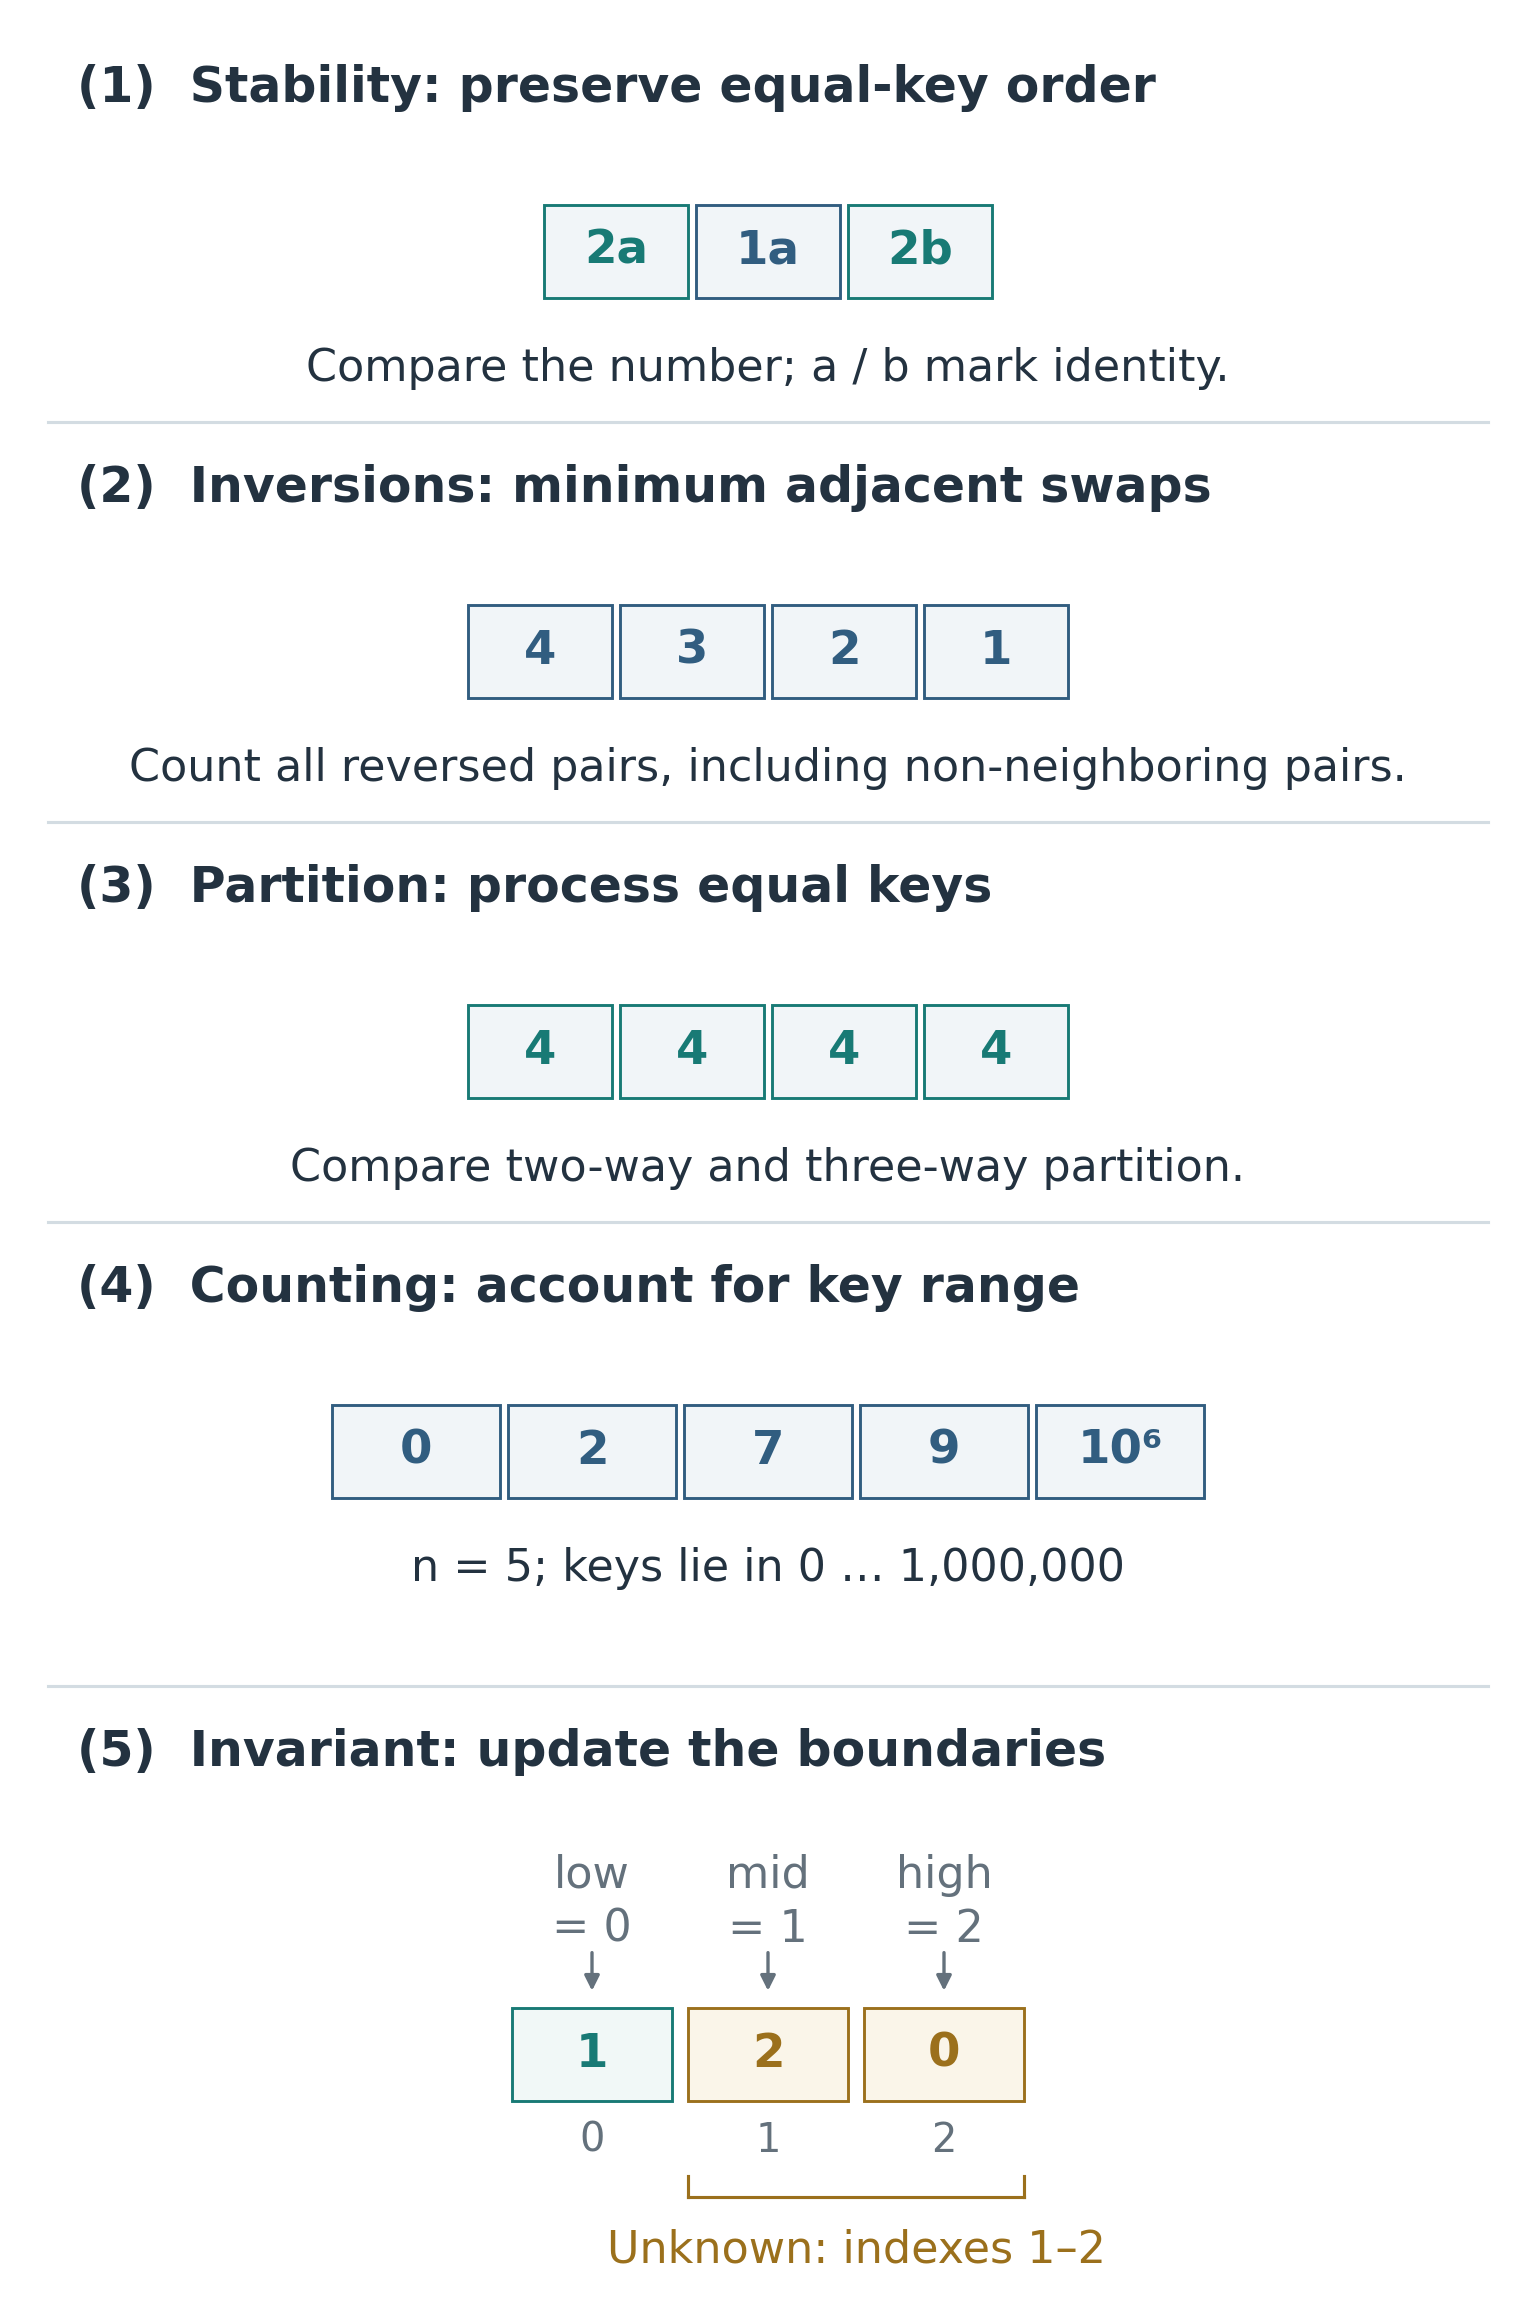

*Figure 8. Record label과 구간 경계를 함께 보면 숫자의 최종 순서만으로는 확인할 수 없는 오류를 찾을 수 있다. Interactive 문제에도 같은 입력을 사용한다.*



## 20. Coding test: Dutch national flag 구현

`0`, `1`, `2`만 들어 있는 배열을 오름차순으로 정렬하자. **In-place**로 처리하고, $O(1)$의 auxiliary space와 한 번의 classification pass만 사용해야 한다. 정렬 함수는 호출하면 안 된다. 개수를 센 뒤 다시 쓰는 방법도 linear time의 올바른 two-pass solution이다. 다만 이 문제에서는 한 번의 classification pass로 끝내도록 partition invariant를 구현해야 한다.

예를 들어 `[2, 0, 2, 1, 1, 0]`을 `[0, 0, 1, 1, 2, 2]`로 바꿔야 한다. 빈 배열, 한 가지 값만 있는 배열, 중복이 많은 배열도 입력할 수 있다. Stability는 요구하지 않는다. 함수는 **원래 list 자체를 수정하고 같은 list를 반환**해야 한다. 새 list를 만들어 반환하면 이 API 조건에 맞지 않는다.

**Dutch national flag**는 pivot을 `1`로 고정한 3-way partition이다. 배열을 0, 1, unknown, 2의 네 구간으로 나누고 다음 invariant를 유지한다.

$$
\begin{array}{ccl}
[0,\mathrm{low})&:&0,\\
[\mathrm{low},\mathrm{mid})&:&1,\\
[\mathrm{mid},\mathrm{high}]&:&\text{unknown},\\
(\mathrm{high},n)&:&2.
\end{array}
\tag{31}
$$

코드에서 결정할 부분은 세 가지다. Unknown 구간의 끝점을 loop 조건에 포함할지, 0을 배치한 뒤 scan 위치를 옮길지, 2를 끝으로 보낸 뒤에도 scan 위치를 옮길지 정해야 한다.


아래 starter에는 세 가지 선택을 확인하는 TODO가 있으며, 일부는 일부러 틀리게 해 두었다. 그대로 실행하면 일부 테스트에서 실패한다. TODO 1–3을 모두 확인하고 잘못된 선택을 고친 뒤 테스트 cell을 다시 실행해 보자. Counter와 iteration 제한은 이미 들어 있다. 원래 list를 직접 정렬하고 같은 list를 반환해야 한다. 테스트마다 실행 결과와 정답, 실패 이유를 확인할 수 있다. 정답 코드는 별도의 reference solution cell에 있다.


In [17]:
def sort_colors(nums, *, stats=None):
    """Fill the loop condition and the two mid updates below.

    Invariant (half-open intervals except for the unknown region):
      nums[:low] == 0; nums[low:mid] == 1;
      nums[mid:high+1] is unclassified; nums[high+1:] == 2.
    The judge's counters are not required workspace for the algorithm.
    """
    if any(type(x) is not int or x not in (0, 1, 2) for x in nums):
        raise ValueError("Each item must be 0, 1, or 2")
    low, mid, high = 0, 0, len(nums) - 1
    iterations = writes = 0
    stop = None
    while mid < high:  # TODO 1: Is equality still a nonempty unknown interval?
        # Safety checks diagnose wrong choices instead of hanging or indexing out
        # of range. They are not additional steps needed by the correct algorithm.
        if iterations >= len(nums):
            stop = "n-iteration safety budget reached"
            break
        if not (0 <= low <= mid <= high < len(nums)):
            stop = "pointer invariant 0 <= low <= mid <= high < n failed"
            break
        iterations += 1
        if nums[mid] == 0:
            if low != mid:
                nums[low], nums[mid] = nums[mid], nums[low]
                writes += 2
            low += 1
            mid += 1  # TODO 2: Keep this update, or leave mid unchanged?
        elif nums[mid] == 1:
            mid += 1
        else:
            if mid != high:
                nums[mid], nums[high] = nums[high], nums[mid]
                writes += 2
            high -= 1
            mid += 1  # TODO 3: Keep this update, or recheck the incoming value?
    if stats is not None:
        stats.update(iterations=iterations, writes=writes, done=mid > high,
                     low=low, mid=mid, high=high, stop=stop)
    return nums


In [18]:
CASES = [
    ("empty", []),
    ("singleton", [2]),
    ("sorted", [0, 0, 1, 1, 2, 2]),
    ("reverse", [2, 2, 1, 1, 0, 0]),
    ("recheck", [1, 2, 0]),
    ("all-twos", [2, 2, 2, 2]),
    ("mixed", [2, 0, 2, 1, 1, 0]),
    ("long-cycle", [2, 0, 1] * 8),
]


CASE_PURPOSES = {
    "empty": "An empty unknown interval needs no iteration.",
    "singleton": "The last unknown record must still be classified.",
    "sorted": "Already sorted keys still have to satisfy the partition contract.",
    "reverse": "Swaps must preserve all three classified regions.",
    "recheck": "A value arriving from high is not classified yet.",
    "all-twos": "Moving high alone must empty an all-2 unknown interval.",
    "mixed": "All three branches must cooperate without skipping a record.",
    "long-cycle": "The same rules must stay within n iterations and 2n writes.",
}


def run_tests(solver, verbose=True):
    """The counter checks supplement examples; they are not a workspace proof."""
    results = []
    for name, original in CASES:
        values, stats = original.copy(), {}
        identity = id(values)
        error = None
        try:
            returned = solver(values, stats=stats)
            correct = values == sorted(original)
            same_list = returned is values and id(values) == identity
            iterations_ok = stats.get("iterations", float("inf")) <= len(values)
            writes_ok = stats.get("writes", float("inf")) <= 2 * len(values)
            passed = (correct and same_list and iterations_ok and writes_ok
                      and stats.get("done") is True and not stats.get("stop"))
            if stats.get("stop"):
                reason = stats["stop"]
            elif not stats.get("done"):
                reason = (f"unknown interval [{stats.get('mid')}, "
                          f"{stats.get('high')}] is not empty")
            elif not correct:
                reason = "output/return contract failed; inspect the incoming value after a 2-swap"
            elif not same_list:
                reason = "return the original list object, not a replacement or None"
            elif not iterations_ok or not writes_ok:
                reason = "linear-work budget exceeded"
            else:
                reason = "sorted in place; unknown interval empty; work within budget"
        except Exception as exc:
            error = f"{type(exc).__name__}: {exc}"
            reason = error
            passed = False
        result = dict(id=name, passed=passed, actual=values,
                      expected=sorted(original), error=error, reason=reason, **stats)
        results.append(result)
        if verbose:
            print(f"{name}: {'PASS' if passed else 'FAIL'}; "
                  f"result={values}; iterations={stats.get('iterations', '?')}" +
                  f"; writes={stats.get('writes', '?')}; {reason}")
            print(f"  Checks: {CASE_PURPOSES[name]} Expected: {sorted(original)}")
    return results


starter_results = run_tests(sort_colors)


empty: PASS; result=[]; iterations=0; writes=0; sorted in place; unknown interval empty; work within budget
  Checks: An empty unknown interval needs no iteration. Expected: []
singleton: FAIL; result=[2]; iterations=0; writes=0; unknown interval [0, 0] is not empty
  Checks: The last unknown record must still be classified. Expected: [2]
sorted: PASS; result=[0, 0, 1, 1, 2, 2]; iterations=5; writes=2; sorted in place; unknown interval empty; work within budget
  Checks: Already sorted keys still have to satisfy the partition contract. Expected: [0, 0, 1, 1, 2, 2]
reverse: FAIL; result=[0, 0, 1, 1, 2, 2]; iterations=3; writes=4; unknown interval [3, 3] is not empty
  Checks: Swaps must preserve all three classified regions. Expected: [0, 0, 1, 1, 2, 2]
recheck: FAIL; result=[1, 0, 2]; iterations=2; writes=2; output/return contract failed; inspect the incoming value after a 2-swap
  Checks: A value arriving from high is not classified yet. Expected: [0, 1, 2]
all-twos: PASS; result=[2, 

#### Reference solution


In [19]:
def reference_sort_colors(nums, *, stats=None):
    """Reference solution. Read after trying the exercise."""
    if any(type(x) is not int or x not in (0, 1, 2) for x in nums):
        raise ValueError("Each item must be 0, 1, or 2")
    low, mid, high = 0, 0, len(nums) - 1
    iterations = writes = 0
    while mid <= high:
        iterations += 1
        if nums[mid] == 0:
            if low != mid:
                nums[low], nums[mid] = nums[mid], nums[low]
                writes += 2
            low += 1
            mid += 1  # The moved-in value was in the already-classified 1 region.
        elif nums[mid] == 1:
            mid += 1
        else:
            if mid != high:
                nums[mid], nums[high] = nums[high], nums[mid]
                writes += 2
            high -= 1
            # The moved-in value came from the unknown region. Inspect it next.
    if stats is not None:
        stats.update(iterations=iterations, writes=writes, done=mid > high,
                     low=low, mid=mid, high=high, stop=None)
    return nums


reference_results = run_tests(reference_sort_colors)
assert all(row['passed'] for row in reference_results)


empty: PASS; result=[]; iterations=0; writes=0; sorted in place; unknown interval empty; work within budget
  Checks: An empty unknown interval needs no iteration. Expected: []
singleton: PASS; result=[2]; iterations=1; writes=0; sorted in place; unknown interval empty; work within budget
  Checks: The last unknown record must still be classified. Expected: [2]
sorted: PASS; result=[0, 0, 1, 1, 2, 2]; iterations=6; writes=2; sorted in place; unknown interval empty; work within budget
  Checks: Already sorted keys still have to satisfy the partition contract. Expected: [0, 0, 1, 1, 2, 2]
reverse: PASS; result=[0, 0, 1, 1, 2, 2]; iterations=6; writes=4; sorted in place; unknown interval empty; work within budget
  Checks: Swaps must preserve all three classified regions. Expected: [0, 0, 1, 1, 2, 2]
recheck: PASS; result=[0, 1, 2]; iterations=3; writes=4; sorted in place; unknown interval empty; work within budget
  Checks: A value arriving from high is not classified yet. Expected: [0, 

브라우저에서는 이 세 가지 선택을 여덟 test case로 검사한다. 임의의 Python 코드를 실행하는 방식은 아니다. 각 결과를 펼치면 입력, 실행 결과, 정답과 함께 마지막 pointer 위치, iteration 수, record 쓰기 횟수가 나온다. 숫자가 우연히 정렬됐더라도 마지막 record를 분류하지 않았다면 FAIL이다. LIMIT는 iteration 안전 한도에 도달했다는 뜻이고, INVARIANT는 pointer 관계가 잘못됐다는 뜻이다.

[Python starter](https://pilkwangkim.github.io/assets/code/sorting-code-test.py)에는 counter와 안전장치가 구현돼 있어 그대로 실행할 수 있다. TODO로 표시한 세 가지 선택 중 일부는 일부러 틀리게 해 두었다. TODO 1–3을 모두 확인하고 잘못된 선택을 고친 뒤 테스트를 다시 실행하면 된다. Notebook에도 같은 starter와 테스트, 별도의 reference solution이 들어 있다. 처음 설정으로도 여덟 test case 중 세 개는 통과한다. 몇 개를 통과했다고 끝내지 말고, 여덟 개를 모두 통과시킨 뒤 invariant를 이용해 다른 입력에서도 성립하는 이유를 설명해 보자.


#### Reference solution과 termination proof


In [20]:
# This reference does not replace the editable sort_colors starter.
def article_sort_colors(a):
    """Sort 0/1/2 in place in one classification pass; return a."""
    low = mid = 0
    high = len(a) - 1
    while mid <= high:
        if a[mid] == 0:
            a[low], a[mid] = a[mid], a[low]
            low += 1
            mid += 1
        elif a[mid] == 1:
            mid += 1
        elif a[mid] == 2:
            a[mid], a[high] = a[high], a[mid]
            high -= 1  # The incoming value at mid is still unknown.
        else:
            raise ValueError("colors must be 0, 1, or 2")
    return a

assert article_sort_colors([2, 0, 2, 1, 1, 0]) == [0, 0, 1, 1, 2, 2]
assert article_sort_colors([]) == []
assert article_sort_colors([2, 2, 0]) == [0, 2, 2]


0을 `a[low]`와 swap할 때, `low < mid`이면 `mid`로 들어오는 값은 이미 1로 분류된 값이다. 두 index가 같다면 0을 자기 자신과 바꾼 것이므로 확인할 새 값이 없다. 어느 쪽이든 `low`와 `mid`를 함께 옮겨도 된다. 반면 2를 `a[high]`와 swap하면 unknown 구간에 있던 값이 `mid`로 들어온다. 0, 1, 2 중 무엇인지 아직 모르므로 `mid`를 옮기면 안 된다.

아직 분류하지 않은 record의 수를 다음과 같이 두자.

$$
U=\mathrm{high}-\mathrm{mid}+1.
\tag{32}
$$

처음에는 $U=n$이다. 세 branch 중 어느 것을 실행해도 네 구간의 invariant는 유지되고 $U$는 정확히 하나 줄어든다. 따라서 classification을 정확히 $n$번 수행하면 $U=0$이 되어 loop가 끝난다. 이때 배열은 0, 1, 2 순서로 나뉘며, swap만 했으므로 record가 빠지거나 추가되지도 않는다. 따라서 time complexity는 $\Theta(n)$이고 auxiliary space는 $O(1)$이다.

Linear time에 끝나는 이유는 각 record를 정해진 세 종류 중 하나로 분류하기 때문이다. 이는 임의의 서로 다른 key를 정렬할 때의 comparison lower bound와 모순되지 않는다. 이 문제에서는 그 lower bound를 구할 때 고려한 $n!$가지 상대 순서를 구별할 필요가 없다.



순서가 뒤집힌 이웃을 swap하면 inversion 하나가 줄어든다. Merge는 이미 정렬된 두 구간을 이용하므로 한 level의 모든 record를 linear time에 처리한다. Partition은 서로 다른 구간 사이의 순서를 먼저 확정한다. Heap은 다음 최댓값을 꺼내는 데 필요한 순서만 유지한다. Counting sort와 radix sort는 비교 결과뿐 아니라 key의 표현도 이용한다. 이처럼 활용하는 정보와 입력 조건이 다르기 때문에 time complexity에도 차이가 생긴다.

## 참고문헌

- [Sedgewick·Wayne, elementary sorting methods](https://algs4.cs.princeton.edu/21elementary/): selection, insertion, Shell sort와 구현 조건.
- [Princeton Merge API](https://algs4.cs.princeton.edu/code/javadoc/edu/princeton/cs/algs4/Merge.html): stable merge의 time·space complexity.
- [Sedgewick·Wayne, quicksort](https://algs4.cs.princeton.edu/23quicksort/index.php): partition과 같은 key의 처리.
- [Sedgewick·Wayne, priority queues](https://algs4.cs.princeton.edu/24pq/): binary heap, bottom-up build, heapsort.
- [MIT 6.006, lower bounds and linear-time sorting](https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-fall-2011/resources/lecture-7-counting-sort-radix-sort-lower-bounds-for-sorting/): comparison model, counting, radix.
- [Princeton string-sorting lecture](https://www.cs.princeton.edu/courses/archive/fall12/cos226/lectures/51StringSorts-2x2.pdf): key-indexed counting과 LSD radix.
- [Python Sorting HOWTO](https://docs.python.org/3/howto/sorting.html): stability, key function, Python API.
- [CPython 3.14 sorting design](https://github.com/python/cpython/blob/3.14/Objects/listsort.txt): adaptive run, merge policy, memory 사용.
- [David Musser, generic algorithms](https://www.cs.rpi.edu/~musser/gp/index_1.html): introspective sorting을 처음 제안한 자료.
- [NIST Dictionary of Algorithms and Data Structures, bitonic sort](https://xlinux.nist.gov/dads/HTML/bitonicSort.html): sorting network와 parallel 용어.
